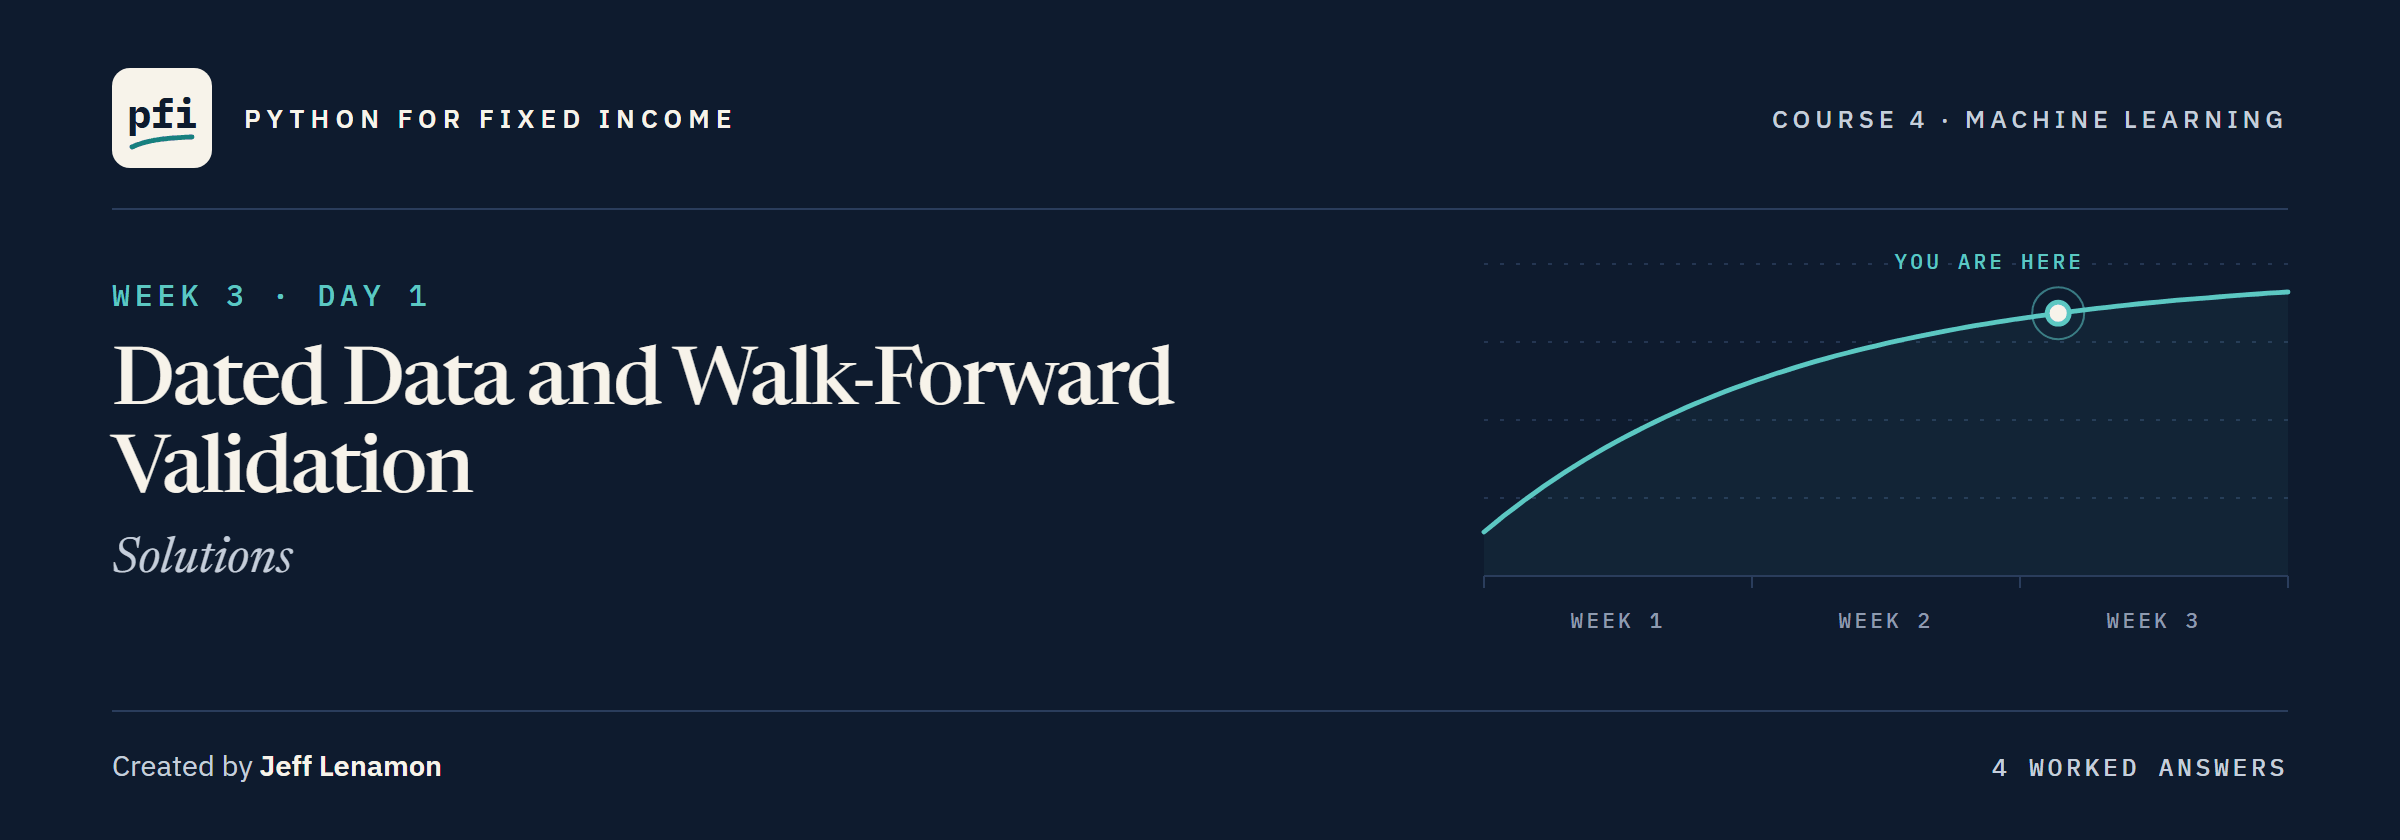

# Dated Data and Walk-Forward Validation: Solutions

Week 3, Day 1. The full notebook with every exercise worked. Try each one yourself first.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course04_machine_learning/week3/day1/11_dated_data_and_walk_forward_validation_solutions.ipynb)

# Problem Statement

## Business Context

Every corporate spread on the desk is quoted over a Treasury yield.
A desk quant asks a question about the curve's shape: given the 2 Yr and the 10 Yr on a date, what 30 Yr goes with them on that same date?
For ten days the course scored bonds and card accounts, rows with no order; today's rows are dates.
All three yields sit on one row, so the model's output is a fitted 30 Yr yield given the same day's 2 Yr and 10 Yr.
It describes how the long end sat against them inside the file's span, and a gap between actual and fitted is the model's miss, not a view on rates.

## Objectives

Score a regression tree and a straight line with shuffled folds, then again in time order.
Find out why the two scores differ, fit ridge and lasso where the tenors are near-copies, catch lookahead hiding in a feature, and test whether the misses run.

## Data Dictionary

`treasury_par_yields.csv`, one row per market date:

1. `date`: the market date, 2015-01-02 to 2026-10-02
2. `1 Mo`, `3 Mo`, `6 Mo`, `1 Yr`, `2 Yr`, `3 Yr`, `5 Yr`, `7 Yr`, `10 Yr`, `20 Yr`, `30 Yr`: par yields, percent
3. `1.5 Month`, `2 Mo`, `4 Mo`: tenors that start partway through the file, not used

Each tenor's daily change, in bp, is made in the notebook.

# Setting Up

## Course Setup

Run this cell and move on: it fixes the seed and finds the course data.

In [1]:
# today's setup: the thread settings, the seed, and where the course data lives
import os
from pathlib import Path

# one thread for the maths libraries, so every run prints the same last digits (this must run before numpy is imported)
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

# the seed: one number for every random choice, so every run makes the same choices
SEED = 42

# the course data: the repo's data folder on your machine, GitHub in Colab
DATA = "../../../data/"
if not Path(DATA + "benchmark.csv").exists():
    DATA = "https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/"

## Importing the Libraries

In [2]:
# to load and work with the data
import numpy as np
import pandas as pd

# to draw charts, and a slider
import matplotlib.pyplot as plt
import seaborn as sns
from ipywidgets import interact

# to cut the dates into folds and score a model on each fold
from sklearn.model_selection import KFold, TimeSeriesSplit, cross_val_score, cross_validate

# the models: a regression tree, a straight line, and Day 5's ridge and lasso, each in a pipeline
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Day 3's variance inflation factor, and the Durbin-Watson statistic
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.stattools import durbin_watson

# one look for every chart
sns.set_theme(style="whitegrid")
sns.set_palette("colorblind")
plt.rcParams["figure.figsize"] = (10, 5)

# Loading the Data

## Reading the Treasury File

`parse_dates=["date"]` reads the date column as dates, and `index_col="date"` makes it the row labels, as in Course 1's time series notebook.

In [3]:
# one row per market date, labelled by its date
yields = pd.read_csv(DATA + "treasury_par_yields.csv", parse_dates=["date"], index_col="date")

# Data Overview

## Checking the Shape and the Dates

Q. Is there one row per date, in order?

In [4]:
# rows and columns, the first and last date, and whether every date is unique and in order
print(yields.shape)
print("From", yields.index.min().date(), "to", yields.index.max().date())
print("Each date once:", yields.index.is_unique, " In order:", yields.index.is_monotonic_increasing)

(2940, 14)
From 2015-01-02 to 2026-10-02
Each date once: True  In order: True


## Checking for Missing Values

In [5]:
# empty cells per column, and the first date of each column that starts partway
missing = yields.isnull().sum()
print(missing[missing > 0])
for column in ["2 Mo", "4 Mo", "1.5 Month"]:
    print(column, "starts on", yields[column].first_valid_index().date())

1.5 Month    2532
2 Mo          949
4 Mo         1951
dtype: int64
2 Mo starts on 2018-10-16
4 Mo starts on 2022-10-19
1.5 Month starts on 2025-02-18


Three tenors start partway through; the other eleven have a yield on every date.

**Eleven tenors are complete and the dates are in order, so we keep those eleven and look at what makes dated rows different.**

## Checking the Statistical Summary

In [6]:
# the eleven complete tenors, then each one's mean, lowest and highest yield in percent
curve = yields.dropna(axis=1)
curve.describe().T[["mean", "min", "max"]].round(2)

,mean,min,max
1 Mo,2.10,0.00,6.02
3 Mo,2.16,0.00,5.63
6 Mo,2.22,0.02,5.61
1 Yr,2.24,0.04,5.49
2 Yr,2.28,0.09,5.19
3 Yr,2.34,0.10,5.03
5 Yr,2.47,0.19,5.09
7 Yr,2.64,0.36,5.19
10 Yr,2.76,0.52,5.29
20 Yr,3.13,0.87,5.68


The 30 Yr runs from 0.99 to 5.64 percent, the 2 Yr from 0.09 to 5.19.

# Exploratory Data Analysis

## Univariate Analysis

### The Whole Curve, Date by Date

`imshow` paints a table as coloured squares: here one column of colour per date, one row per tenor.
`origin="lower"` puts the table's first row, the 1 Mo, at the bottom.

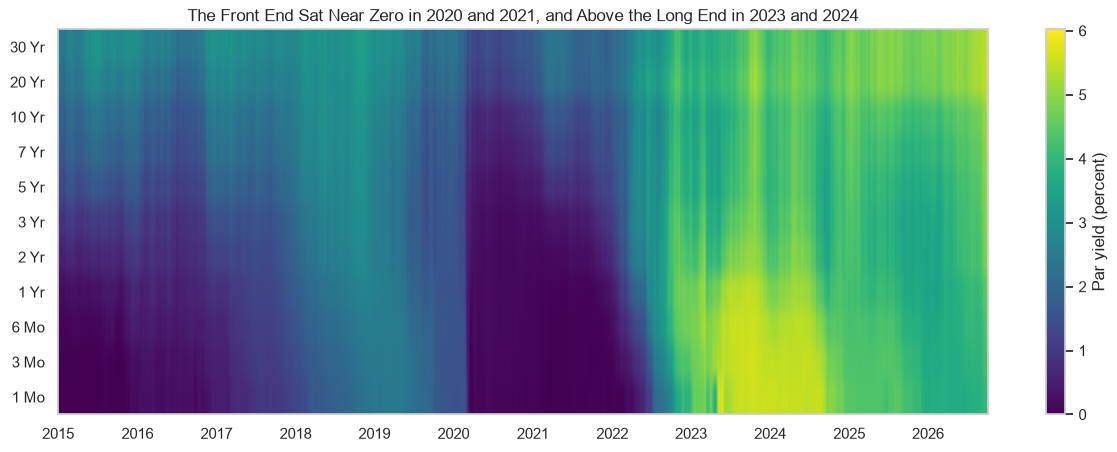

In [7]:
# the row number of each year's first date, to label the time axis
year_starts = pd.Series(range(len(curve)), index=curve.index).groupby(curve.index.year).first()

# the whole file as one picture: dates across, tenors up, colour by yield
fig, ax = plt.subplots(figsize=(15, 5))
painted = ax.imshow(curve.T, aspect="auto", cmap="viridis", origin="lower")
fig.colorbar(painted, label="Par yield (percent)")
ax.set_yticks(range(11), curve.columns)
ax.set_xticks(year_starts.values, year_starts.index)
ax.grid(False)
ax.set_title("The Front End Sat Near Zero in 2020 and 2021, and Above the Long End in 2023 and 2024")
plt.show()

In [8]:
# dates on which the 2 Yr sat above the 10 Yr, and the 30 Yr's lowest and highest
above = curve["2 Yr"] > curve["10 Yr"]
print("2 Yr above 10 Yr:", above.sum(), "dates, from", above[above].index.min().date(), "to", above[above].index.max().date())
print("30 Yr low:", curve["30 Yr"].min(), "on", curve["30 Yr"].idxmin().date())
print("30 Yr high:", curve["30 Yr"].max(), "on", curve["30 Yr"].idxmax().date())

2 Yr above 10 Yr: 544 dates, from 2019-08-27 to 2024-09-05
30 Yr low: 0.99 on 2020-03-09
30 Yr high: 5.64 on 2026-09-30


The front end sat near zero through 2020 and 2021, the dark band low in the middle.

The 2 Yr sat above the 10 Yr on 544 dates, the first in 2019 and the last in 2024: in 2023 and 2024 the short tenors are brighter than the long ones.

The 30 Yr's low was 0.99 percent on 2020-03-09 and its high 5.64 percent on 2026-09-30.

### How Close Is Each Date to the Day Before?

Q. How alike are two neighbouring dates?

`.autocorr(lag)` is the correlation of a column with itself shifted `lag` rows: lag 1 pairs each date with the date before.

In [9]:
# the 30 Yr each date, and its daily change in bp
thirty = curve["30 Yr"]
change_bp = thirty.diff() * 100
print("Lag-1 correlation, level:", round(thirty.autocorr(1), 4), " daily change:", round(change_bp.autocorr(1), 4))
print("Median daily move:", round(change_bp.abs().median(), 1), "bp")

Lag-1 correlation, level: 0.9989  daily change: -0.0207
Median daily move: 3.0 bp


A **lag plot** draws each value against the value one row before.
A **correlogram** draws the correlation at every lag; `ax.stem` draws each one as a stalk from zero.

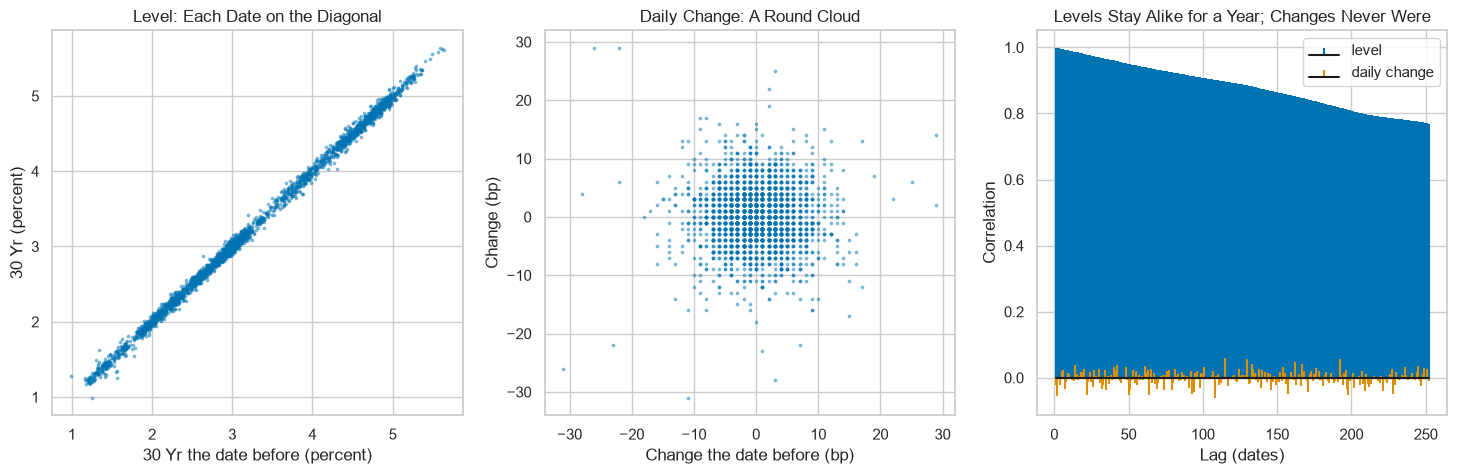

Level at lags 21, 63, 252: 0.9794 0.9384 0.7695


In [10]:
# lag plots of the level and the change, then the correlation at lags 1 to 252 (about a year of dates)
lags = range(1, 253)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].scatter(thirty.shift(1), thirty, s=3, alpha=0.4)
axes[1].scatter(change_bp.shift(1), change_bp, s=3, alpha=0.4)
# linefmt colours the stalks, markerfmt=" " leaves off the dot on top, basefmt draws the zero line in black
axes[2].stem(lags, [thirty.autocorr(lag) for lag in lags], linefmt="C0-", markerfmt=" ", basefmt="k-", label="level")
axes[2].stem(lags, [change_bp.autocorr(lag) for lag in lags], linefmt="C1-", markerfmt=" ", basefmt="k-", label="daily change")
axes[0].set(xlabel="30 Yr the date before (percent)", ylabel="30 Yr (percent)", title="Level: Each Date on the Diagonal")
axes[1].set(xlabel="Change the date before (bp)", ylabel="Change (bp)", title="Daily Change: A Round Cloud")
axes[2].set(xlabel="Lag (dates)", ylabel="Correlation", title="Levels Stay Alike for a Year; Changes Never Were")
axes[2].legend()
plt.show()
print("Level at lags 21, 63, 252:", round(thirty.autocorr(21), 4), round(thirty.autocorr(63), 4), round(thirty.autocorr(252), 4))

The level sits on the diagonal: a date's 30 Yr is almost the date before's, correlation 0.9989.

It still correlates 0.9794 a month of dates away (21), 0.9384 at 63 and 0.7695 at 252.

The daily change makes a round cloud, correlation -0.0207, and sits near zero at every lag.

**A date's level is a near-copy of the dates around it; its daily change is not. Any split that shuffles dates puts a near-copy of a test date among the training rows.**

## Bivariate Analysis

### The 30 Yr Against the 10 Yr, Coloured by Date

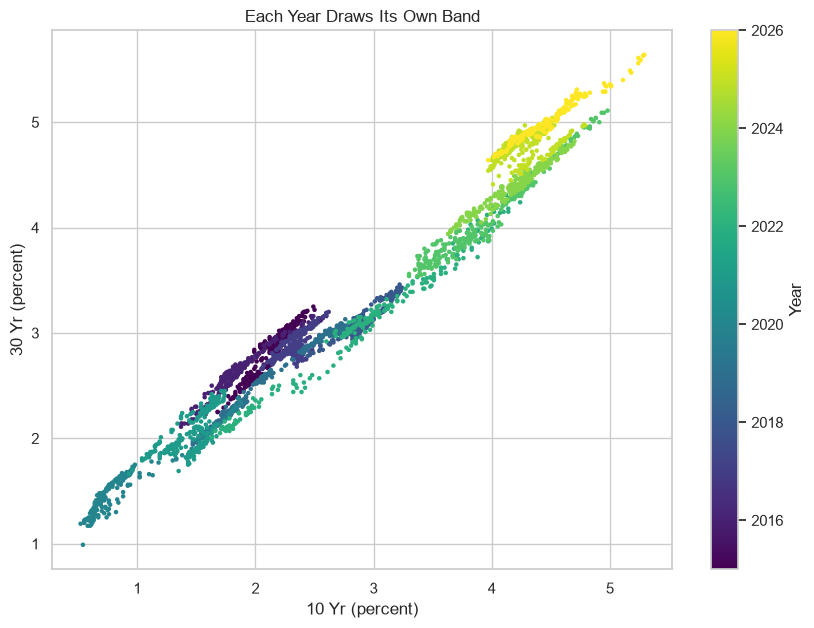

{2015: 70.0, 2016: 76.0, 2017: 56.0, 2018: 20.0, 2019: 44.0, 2020: 67.0, 2021: 61.0, 2022: 16.0, 2023: 14.0, 2024: 20.0, 2025: 48.0, 2026: 54.0}


In [11]:
# each date a dot, coloured by its year
fig, ax = plt.subplots(figsize=(10, 7))
dots = ax.scatter(curve["10 Yr"], curve["30 Yr"], c=curve.index.year, cmap="viridis", s=5)
fig.colorbar(dots, label="Year")
ax.set(xlabel="10 Yr (percent)", ylabel="30 Yr (percent)", title="Each Year Draws Its Own Band")
plt.show()

# the 30 Yr's average gap over the 10 Yr in each year, in bp
gap_bp = (curve["30 Yr"] - curve["10 Yr"]) * 100
print(gap_bp.groupby(curve.index.year).mean().round(0).to_dict())

The 30 Yr sat 70 bp over the 10 Yr on average in 2015, 14 bp in 2023, and 54 bp in 2026.

**On one date the three yields sit close to a plane, and the plane moves from year to year.**

# Data Preparation for Modeling

## Features and Target

In [12]:
# the same day's 2 Yr and 10 Yr as features, the same day's 30 Yr as the target, all in percent
X = curve[["2 Yr", "10 Yr"]]
y = curve["30 Yr"]

**Every number comes from one row, so the model describes a date's curve shape and reads nothing later.**

No split is made here: the folds are the splits.

# Model Building

## A Regression Tree

![A regression tree two questions deep fitted to all 2,940 dates: the root asks whether the 10 Yr is at most 3.340, the left side asks whether it is at most 1.835 and the right side whether it is at most 3.985, and the four leaves output the average 30 Yr of their dates: 1.98 percent on 767 dates, 2.91 on 1,158, 3.85 on 259 and 4.71 on 756](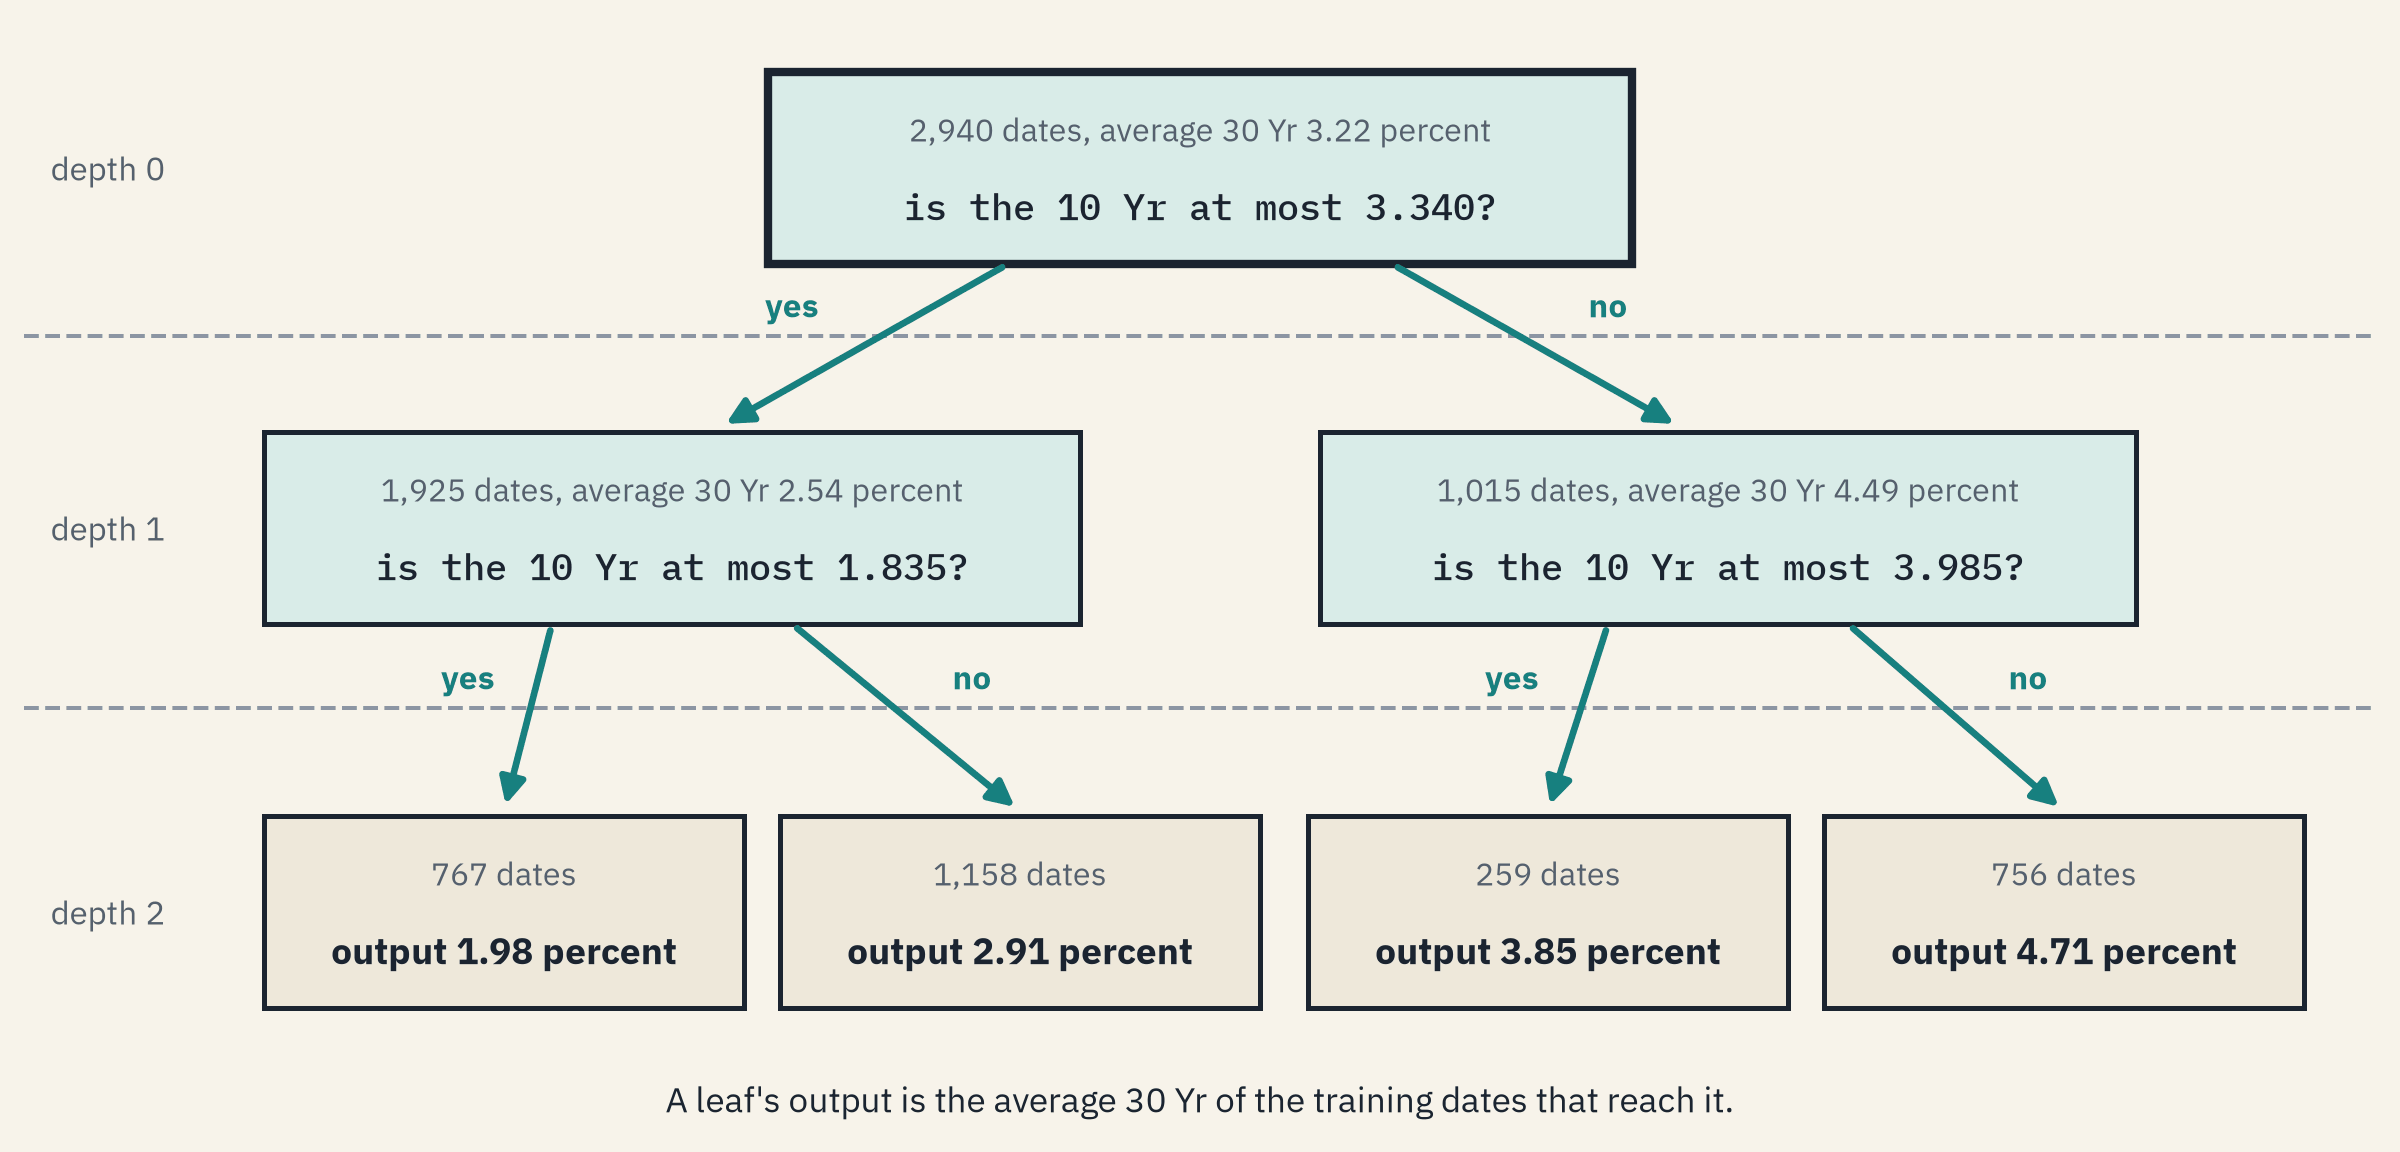)

A `DecisionTreeRegressor` is Day 9's tree with a number as its target.
It picks each split to shrink the squared misses, and a leaf's output is the average 30 Yr of the training dates in it.

In [13]:
# the tree, grown without limits, and Day 1's straight line
tree = DecisionTreeRegressor(random_state=SEED)
line = LinearRegression()

## A Random Split: Five Shuffled Folds

Day 5's `KFold` cuts the rows into five shuffled folds.
`scoring="neg_mean_absolute_error"` names a ready-made score; like Day 5's `make_scorer` it comes back with a minus sign.
Times -100 undoes the sign and turns percent into bp.

In [14]:
# five folds, the dates shuffled with the course seed
kfold = KFold(n_splits=5, shuffle=True, random_state=SEED)

**Predict 1**

The tree knows only the 2 Yr and 10 Yr of each date, and the 30 Yr's median daily move is 3.0 bp.

Q. On five shuffled folds, what is the tree's average miss in bp? Write down a number.

In [15]:
# the tree's MAE on each shuffled fold, in bp
random_tree = -cross_val_score(tree, X, y, cv=kfold, scoring="neg_mean_absolute_error") * 100
random_tree.round(2)

array([3.91, 4.63, 4.63, 4.56, 4.55])

### Interpretation of Scores

In [16]:
# the mean and spread of the five scores, the tree's and then the line's on the same folds
random_line = -cross_val_score(line, X, y, cv=kfold, scoring="neg_mean_absolute_error") * 100
print("Tree: mean", round(random_tree.mean(), 2), "bp, std", round(random_tree.std(), 2))
print("Line: mean", round(random_line.mean(), 2), "bp, std", round(random_line.std(), 2))

Tree: mean 4.45 bp, std 0.28
Line: mean 10.81 bp, std 0.39


The tree misses by 4.45 bp on average, less than half the line's 10.81.

The five folds agree within a fraction of a bp, which looks reliable.

### Why the Tree Looks So Good

Q. How far is a test date from the nearest training date?

In [17]:
# next() takes the first fold the splitter hands out; each test date's distance, in rows, to the nearest training date
train_rows, test_rows = next(kfold.split(X))
distance = pd.Series([np.abs(train_rows - row).min() for row in test_rows])
print(distance.value_counts())

1    571
2     17
Name: count, dtype: int64


In [18]:
# fit the tree on fold 1's training dates; its value for each test date beside the 30 Yr a row either side
tree.fit(X.iloc[train_rows], y.iloc[train_rows])
zoom = pd.DataFrame({"actual": y.iloc[test_rows], "tree": tree.predict(X.iloc[test_rows]),
                     "date before": y.shift(1).iloc[test_rows], "date after": y.shift(-1).iloc[test_rows]})
copied = (zoom["tree"] == zoom["date before"]) | (zoom["tree"] == zoom["date after"])
print("Test dates:", len(zoom), " tree's value equals the 30 Yr of a date either side:", copied.sum())

Test dates: 588  tree's value equals the 30 Yr of a date either side: 154


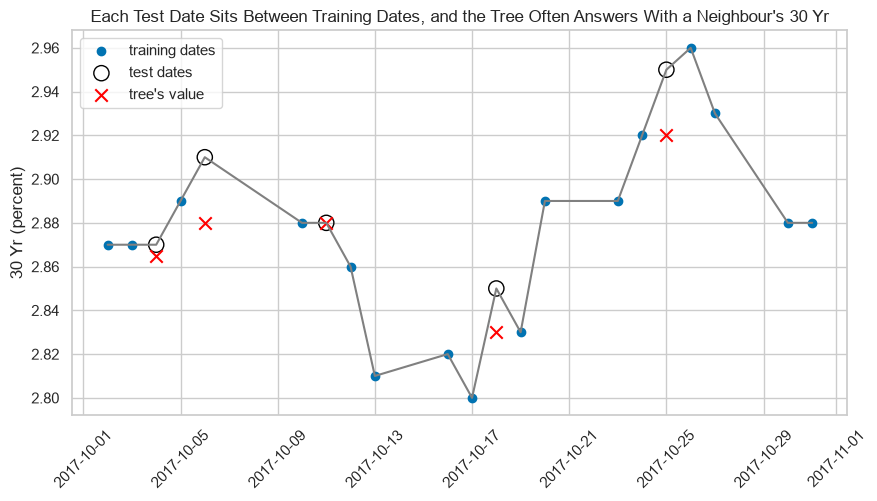

In [19]:
# one month of fold 1: the 30 Yr as a line, training dates as dots, test dates as rings, the tree's values as crosses
month = "2017-10"
training = y.iloc[train_rows].loc[month]
plt.plot(y.loc[month], color="gray")
plt.scatter(training.index, training, color="C0", label="training dates")
plt.scatter(zoom.loc[month].index, zoom.loc[month, "actual"], s=120, facecolor="none", edgecolor="black", label="test dates")
plt.scatter(zoom.loc[month].index, zoom.loc[month, "tree"], marker="x", s=80, color="red", label="tree's value")
plt.xticks(rotation=45)
plt.ylabel("30 Yr (percent)")
plt.title("Each Test Date Sits Between Training Dates, and the Tree Often Answers With a Neighbour's 30 Yr")
plt.legend()
plt.show()

571 of 588 test dates have a training date one row away, and none is more than two away.

On 154 test dates the tree's value is exactly the 30 Yr of the date before or after.

**A random split measures how well a model remembers the dates around a test date. Every training date must come before every test date.**

# Walk-Forward Validation

## Train on the Past, Test on What Follows

![Two strips of dates. Expanding windows: in each fold the training window starts on the first date and grows, and the 126 test dates sit right after it. Rolling windows: the training window keeps one length and slides along, with the test window right after it. A gap of unused dates can sit between the two windows](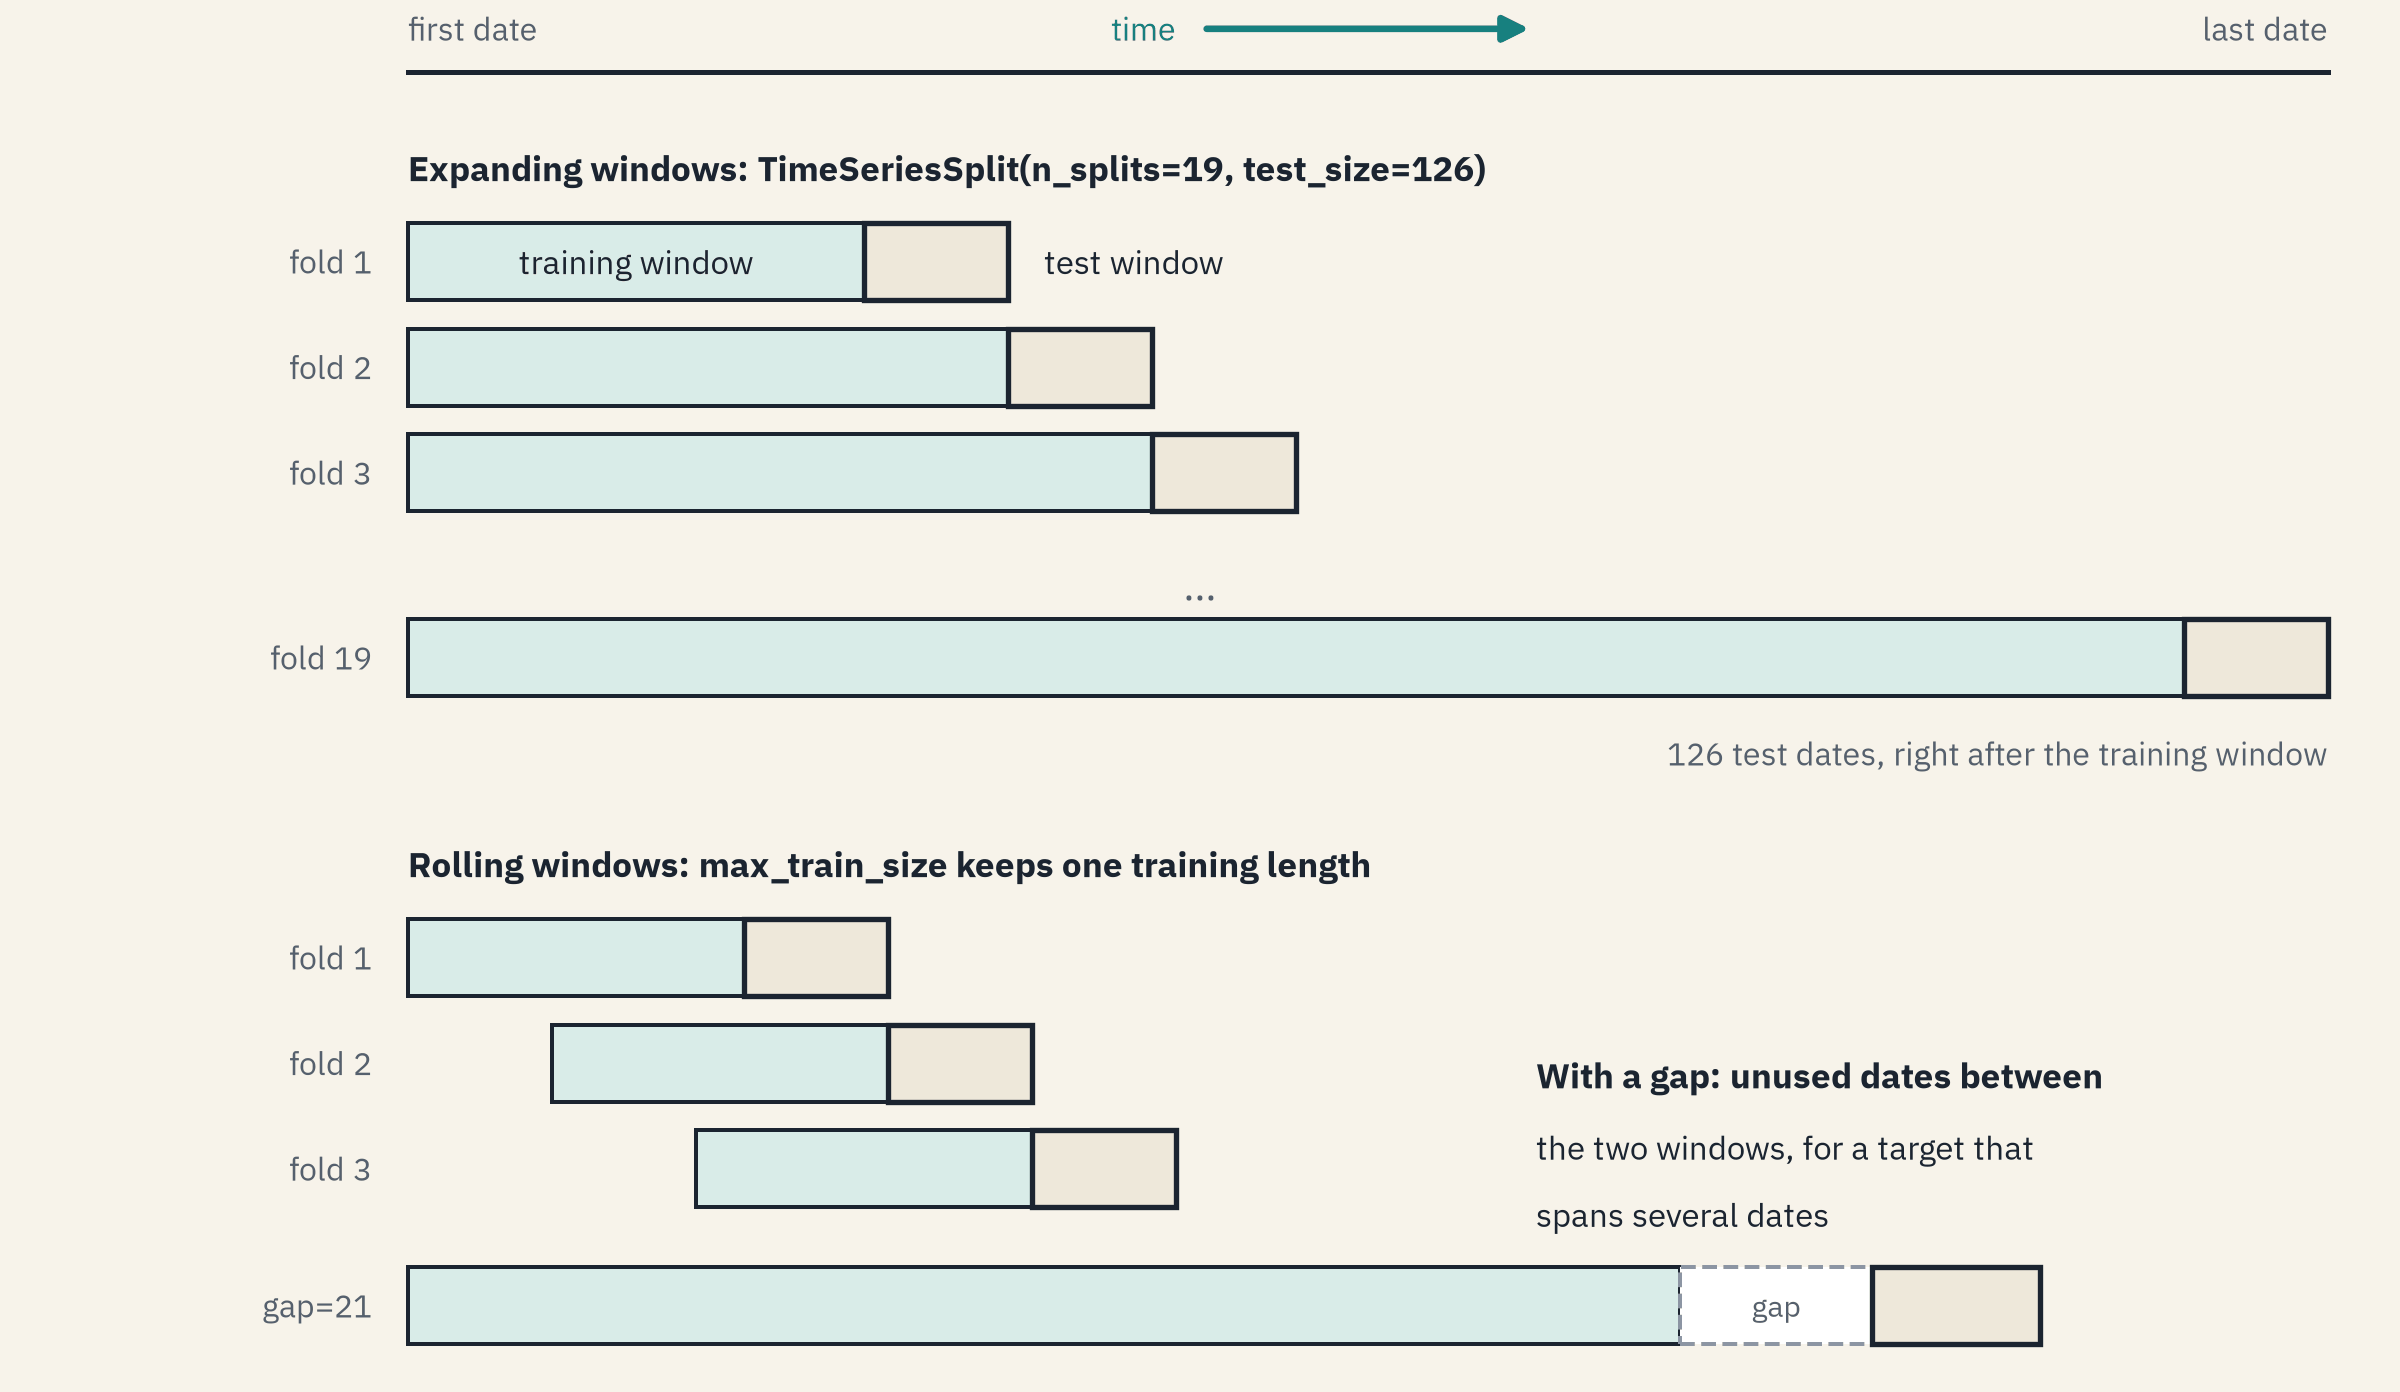)

**Walk-forward validation** fits each fold on a training window and tests it on the window of dates right after it.
An **expanding** window always starts on the first date; a **rolling** window keeps one length and slides.
A **gap** leaves dates unused between the two, for a target that spans several dates.

`TimeSeriesSplit(n_splits=19, test_size=126)` makes 19 expanding folds of 126 test dates, about six months each.

In [20]:
# 19 folds in time order, kept as a list of (training rows, test rows)
wf = TimeSeriesSplit(n_splits=19, test_size=126)
splits = list(wf.split(X))

# the first and the last fold's dates
for fold in [1, 19]:
    fit_rows, scored_rows = splits[fold - 1]
    print("Fold", fold, ": trains on", len(fit_rows), "dates,", X.index[fit_rows[0]].date(), "to", X.index[fit_rows[-1]].date(),
          "; tests", X.index[scored_rows[0]].date(), "to", X.index[scored_rows[-1]].date())

Fold 1 : trains on 546 dates, 2015-01-02 to 2017-03-08 ; tests 2017-03-09 to 2017-09-06
Fold 19 : trains on 2814 dates, 2015-01-02 to 2026-04-03 ; tests 2026-04-06 to 2026-10-02


Every training window starts on 2015-01-02 and grows by 126 dates a fold.

The dates left over go to the first window, 546 of them, so the last test date is the file's last date.

### Three Ways to Cut the Same Dates

A **split matrix** draws one lane per fold and one column per date.

In [21]:
# one lane per fold: 0 where a date is unused, 1 where it trains, 2 where it is tested
def lanes(splitter):
    folds = list(splitter.split(X))
    grid = np.zeros((len(folds), len(X)))
    for k, (fit_rows, scored_rows) in enumerate(folds):
        grid[k, fit_rows] = 1
        grid[k, scored_rows] = 2
    return grid

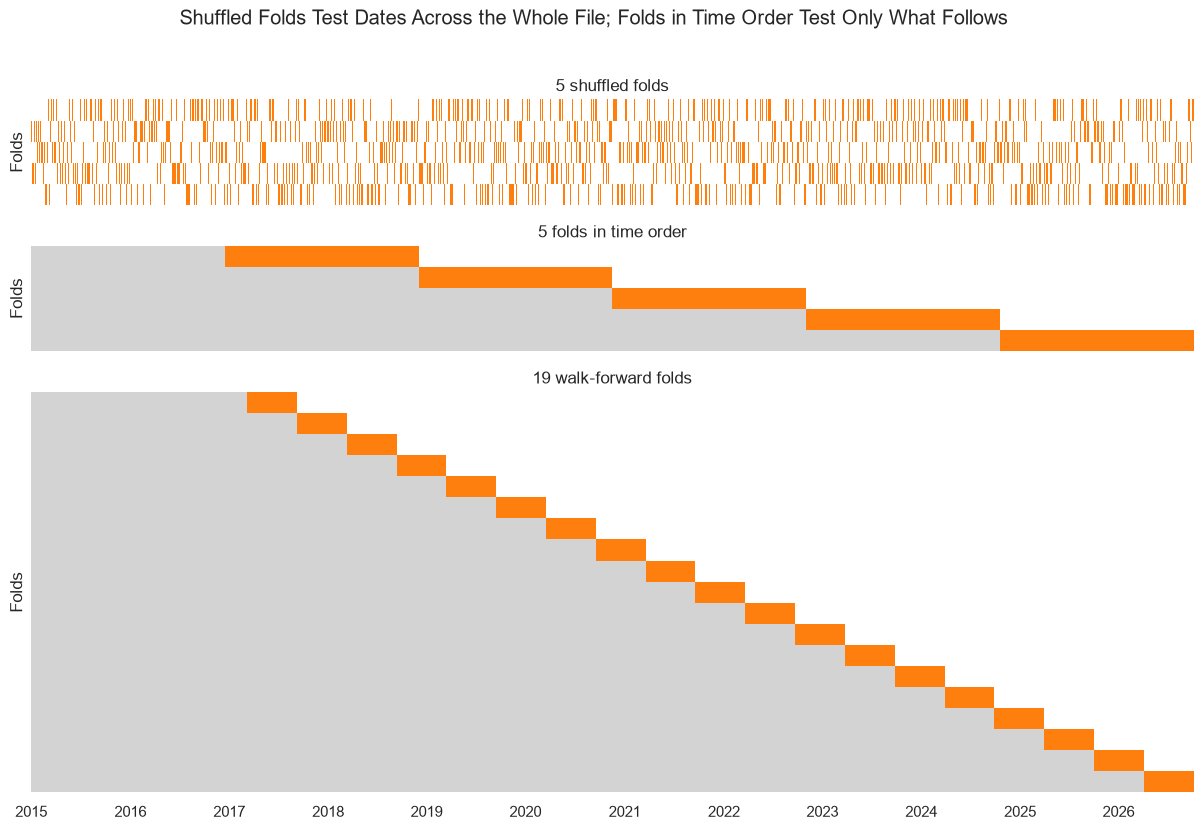

In [22]:
# the three cuts, one panel each, test dates in orange
cuts = {"5 shuffled folds": kfold, "5 folds in time order": TimeSeriesSplit(n_splits=5), "19 walk-forward folds": wf}
fig, axes = plt.subplots(3, 1, figsize=(15, 9), height_ratios=[5, 5, 19], sharex=True)
for ax, (name, splitter) in zip(axes, cuts.items()):
    sns.heatmap(lanes(splitter), cmap=["white", "lightgray", "tab:orange"], cbar=False, xticklabels=False, yticklabels=False, ax=ax)
    ax.set(title=name, ylabel="Folds")
axes[2].set_xticks(year_starts.values, year_starts.index)
fig.suptitle("Shuffled Folds Test Dates Across the Whole File; Folds in Time Order Test Only What Follows")
plt.show()

In time order each lane is grey up to a point, orange right after it, and white beyond: nothing later is fitted.

## Scoring the Tree and the Line in Time Order

**Predict 2**

The tree missed shuffled folds by 4.45 bp.

Q. What is its average miss over the 19 walk-forward folds? Write down a number.

In [23]:
# both models' MAE on each of the 19 folds, in bp
wf_tree = -cross_val_score(tree, X, y, cv=wf, scoring="neg_mean_absolute_error") * 100
wf_line = -cross_val_score(line, X, y, cv=wf, scoring="neg_mean_absolute_error") * 100
print("Tree: mean", round(wf_tree.mean(), 2), "bp, std", round(wf_tree.std(), 2), " folds", round(wf_tree.min(), 1), "to", round(wf_tree.max(), 1))
print("Line: mean", round(wf_line.mean(), 2), "bp, std", round(wf_line.std(), 2), " folds", round(wf_line.min(), 1), "to", round(wf_line.max(), 1))
print("Folds the tree wins:", (wf_tree < wf_line).sum(), "of 19")

Tree: mean 14.84 bp, std 8.12  folds 5.6 to 37.9
Line: mean 14.66 bp, std 6.6  folds 5.0 to 26.8
Folds the tree wins: 7 of 19


### Interpretation of Scores

The tree's miss is 14.84 bp, 3.3 times its shuffled score.

The line, at 14.66, now edges ahead: the ranking flips, and the tree wins only 7 of 19 folds.

The tree's folds run from 5.6 to 37.9 bp: the spread is a finding of its own.

**Two models, each scored only on dates after everything it was fitted on.**

## Where the Misses Sit in Time

`cross_validate` with Day 5's `return_estimator=True` keeps each fold's fitted model.
`return_indices=True` also keeps each fold's training and test rows, under `["indices"]["train"]` and `["indices"]["test"]`.

In [24]:
# the tree on the 19 folds, keeping each fold's fitted tree and its rows
tree_runs = cross_validate(tree, X, y, cv=wf, scoring="neg_mean_absolute_error", return_estimator=True, return_indices=True)
fold_mae = -tree_runs["test_score"] * 100

# each fold's test dates and the tree's MAE, worst first
fold_table = pd.DataFrame({"first test date": [X.index[rows[0]].date() for rows in tree_runs["indices"]["test"]],
                           "last test date": [X.index[rows[-1]].date() for rows in tree_runs["indices"]["test"]],
                           "tree MAE (bp)": fold_mae.round(1)}, index=range(1, 20))
fold_table.sort_values("tree MAE (bp)", ascending=False).head(3)

,first test date,last test date,tree MAE (bp)
18,2025-10-01,2026-04-03,37.9
10,2021-09-17,2022-03-21,27.1
12,2022-09-21,2023-03-24,25.0


A **Gantt chart** draws each fold as a bar along time; `ax.broken_barh` draws a bar from a start and a length.
A colour map called on numbers from 0 to 1, `plt.cm.YlOrRd(...)`, returns one colour per number.

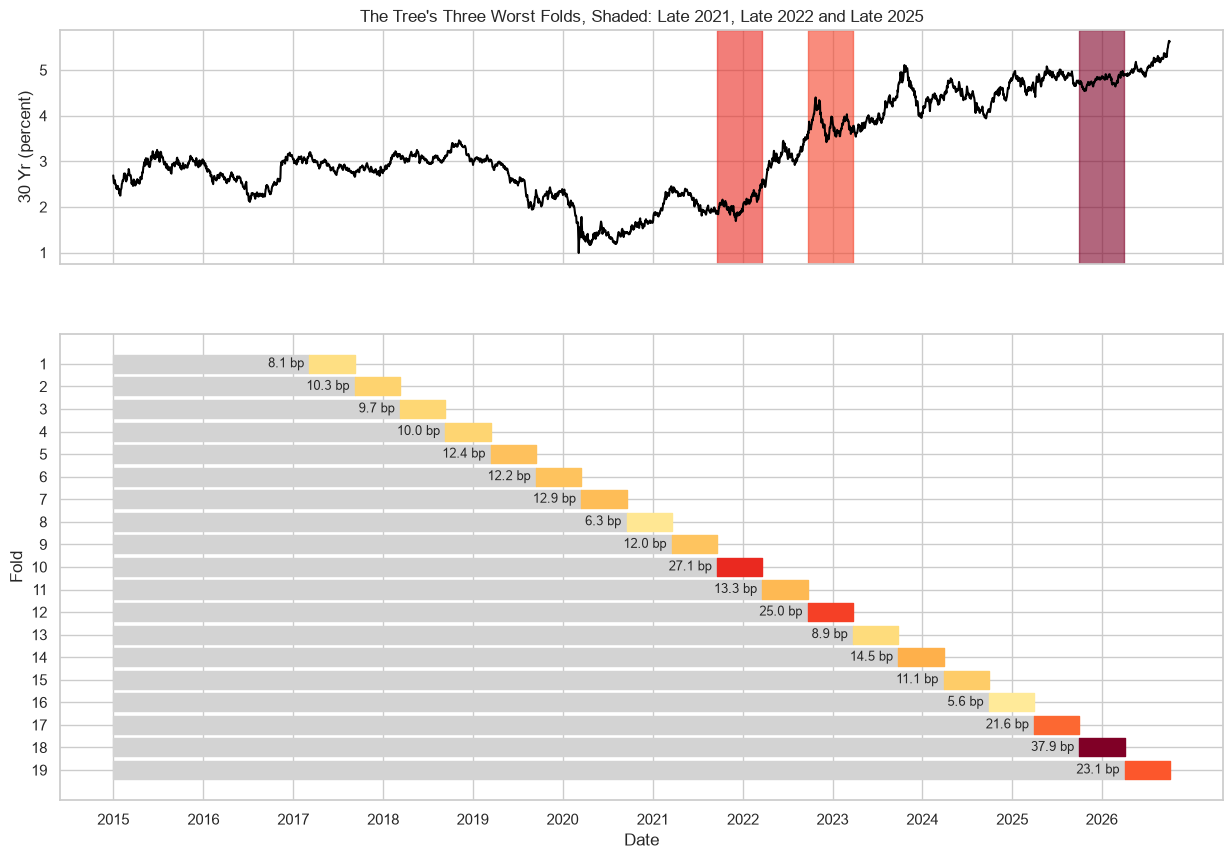

In [25]:
# top: the 30 Yr; below: one lane per fold, training dates grey, test dates coloured by the tree's MAE
colours = plt.cm.YlOrRd(fold_mae / fold_mae.max())
fig, (top, bottom) = plt.subplots(2, 1, figsize=(15, 10), sharex=True, height_ratios=[1, 2])
top.plot(range(len(y)), y, color="black")
for k, (fit_rows, scored_rows) in enumerate(zip(tree_runs["indices"]["train"], tree_runs["indices"]["test"])):
    bottom.broken_barh([(0, len(fit_rows))], (k + 0.6, 0.8), color="lightgray")
    bottom.broken_barh([(scored_rows[0], len(scored_rows))], (k + 0.6, 0.8), color=colours[k])
    bottom.text(scored_rows[0] - 15, k + 1, str(round(fold_mae[k], 1)) + " bp", ha="right", va="center", fontsize=9)
    # shade the folds above 24 bp on the 30 Yr: the three worst
    if fold_mae[k] > 24:
        top.axvspan(scored_rows[0], scored_rows[-1], color=colours[k], alpha=0.6)
top.set(ylabel="30 Yr (percent)", title="The Tree's Three Worst Folds, Shaded: Late 2021, Late 2022 and Late 2025")
bottom.set(ylabel="Fold", xlabel="Date", yticks=range(1, 20))
bottom.set_xticks(year_starts.values, year_starts.index)
bottom.invert_yaxis()
plt.show()

The worst folds are 18 (2025-10-01 to 2026-04-03, 37.9 bp), 10 (2021-09-17 to 2022-03-21, 27.1) and 12 (2022-09-21 to 2023-03-24, 25.0), shaded on the 30 Yr.

The calmest fold, 16, misses by 5.6 bp, about a seventh of fold 18's miss, with the same kind of tree.

**One average over 19 folds hides when a model fails. Two reasons sit behind the bad folds, and the next section finds both.**

## Mean and Spread Under Each Cut

Fold scores are often read as their mean plus or minus one standard deviation.

In [26]:
# each model's fold MAEs under the three cuts, in bp; the five folds in time order are new
in_order = TimeSeriesSplit(n_splits=5)
fold_scores = {("5 shuffled", "tree"): random_tree, ("5 shuffled", "line"): random_line,
               ("5 in time order", "tree"): -cross_val_score(tree, X, y, cv=in_order, scoring="neg_mean_absolute_error") * 100,
               ("5 in time order", "line"): -cross_val_score(line, X, y, cv=in_order, scoring="neg_mean_absolute_error") * 100,
               ("19 walk-forward", "tree"): wf_tree, ("19 walk-forward", "line"): wf_line}
pd.DataFrame({key: [scores.mean(), scores.std()] for key, scores in fold_scores.items()}, index=["mean", "std"]).round(2)

5 shuffled        5 in time order        19 walk-forward       
           tree   line            tree   line            tree   line
mean       4.45  10.81           23.03  25.84           14.84  14.66
std        0.28   0.39            9.31  11.99            8.12   6.60

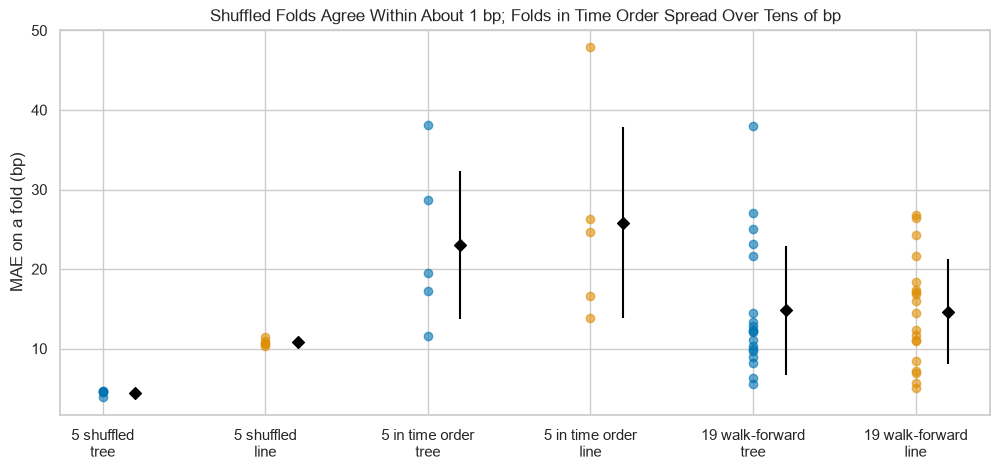

In [27]:
# a dot per fold, and a bar from the mean minus one std to the mean plus one std, in black
plt.figure(figsize=(12, 5))
for position, ((cut, model), scores) in enumerate(fold_scores.items()):
    plt.scatter([position] * len(scores), scores, color="C0" if model == "tree" else "C1", alpha=0.6)
    plt.vlines(position + 0.2, scores.mean() - scores.std(), scores.mean() + scores.std(), color="black")
    plt.scatter(position + 0.2, scores.mean(), color="black", marker="D")
plt.xticks(range(6), [cut + "\n" + model for cut, model in fold_scores])
plt.ylabel("MAE on a fold (bp)")
plt.title("Shuffled Folds Agree Within About 1 bp; Folds in Time Order Spread Over Tens of bp")
plt.show()

On shuffled folds the range is tight, and every fold scores memory.

In time order it depends on which stretch of dates the folds hold.

# Why the Later Folds Are Hard

## Levels the Training Dates Never Reached

In [28]:
# the line on the same 19 folds, kept the same way
line_runs = cross_validate(line, X, y, cv=wf, scoring="neg_mean_absolute_error", return_estimator=True, return_indices=True)
line_fold_mae = -line_runs["test_score"] * 100

# fold 12: the highest 30 Yr among its training dates and among its test dates, in percent
fit_rows, scored_rows = splits[11]
print("Training high:", y.iloc[fit_rows].max(), " Test high:", y.iloc[scored_rows].max())

Training high: 3.59  Test high: 4.4


**Predict 3**

In fold 12 the training dates' highest 30 Yr is 3.59 percent, and the test dates reach 4.40.

Q. Sketch the tree's fitted 30 Yr against the 10 Yr on those test dates, beside the line's.

In [29]:
# one fold: training dates grey, test dates black, the two models' fitted 30 Yr for each test date
def fold_panel(fold, ax):
    fit_rows, scored_rows = splits[fold - 1]
    test_X = X.iloc[scored_rows]
    ax.scatter(X["10 Yr"].iloc[fit_rows], y.iloc[fit_rows], s=3, color="lightgray", label="training dates")
    ax.scatter(test_X["10 Yr"], y.iloc[scored_rows], s=8, color="black", label="test dates, actual")
    ax.scatter(test_X["10 Yr"], tree_runs["estimator"][fold - 1].predict(test_X), s=8, color="C0", label="tree")
    ax.scatter(test_X["10 Yr"], line_runs["estimator"][fold - 1].predict(test_X), s=8, color="C1", label="line")
    ax.axhline(y.iloc[fit_rows].max(), color="gray", linestyle="--", label="training high")
    ax.set(xlabel="10 Yr (percent)", ylabel="30 Yr (percent)",
           title="Fold " + str(fold) + ": tree " + str(round(fold_mae[fold - 1], 1)) + " bp, line " + str(round(line_fold_mae[fold - 1], 1)) + " bp")

### Your Turn: Walk Through the Folds

In [30]:
# move the slider from fold 1 to 19
def draw_fold(fold=12):
    fig, ax = plt.subplots(figsize=(10, 6))
    fold_panel(fold, ax)
    ax.legend()
    plt.show()

interact(draw_fold, fold=(1, 19, 1));

interactive(children=(IntSlider(value=12, description='fold', max=19, min=1), Output()), _dom_classes=('widget…

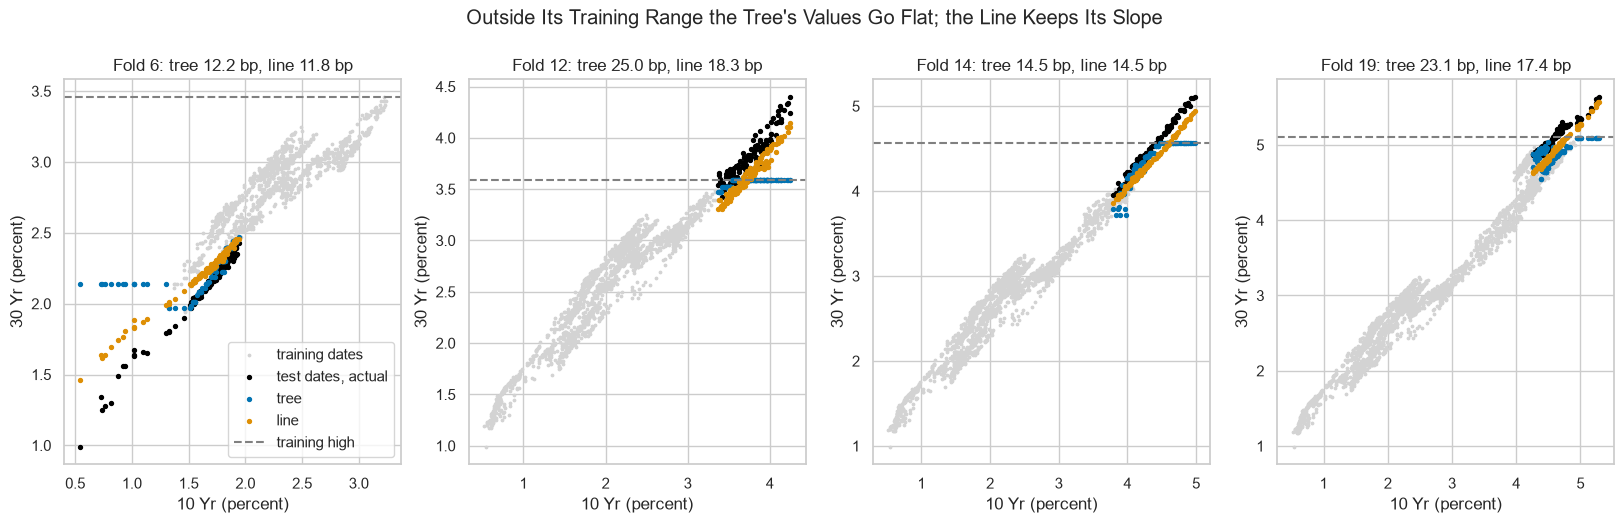

In [31]:
# the slider at folds 6, 12, 14 and 19, drawn as a still picture (sliders do not run on GitHub)
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for fold, ax in zip([6, 12, 14, 19], axes):
    fold_panel(fold, ax)
axes[0].legend()
fig.suptitle("Outside Its Training Range the Tree's Values Go Flat; the Line Keeps Its Slope", y=1.02)
plt.show()

In [32]:
# each fold's training high, the tree's highest value on its test dates, and the test dates outside the training range
table = []
for k, (fit_rows, scored_rows) in enumerate(splits):
    test_y = y.iloc[scored_rows]
    table.append({"fold": k + 1, "training high": y.iloc[fit_rows].max(), "tree's highest": tree_runs["estimator"][k].predict(X.iloc[scored_rows]).max(),
                  "test high": test_y.max(), "dates outside": ((test_y > y.iloc[fit_rows].max()) | (test_y < y.iloc[fit_rows].min())).sum()})
outside = pd.DataFrame(table).set_index("fold")
print("Test dates outside their training range:", outside["dates outside"].sum(), "in", (outside["dates outside"] > 0).sum(), "folds")
outside.loc[[12, 14, 19]]

Test dates outside their training range: 298 in 8 folds


,training high,tree's highest,test high,dates outside
fold,,,,
12,3.59,3.59,4.40,110
14,4.56,4.56,5.11,42
19,5.11,5.09,5.64,55


In fold 12, 110 of 126 test dates sit above the training high of 3.59, and the tree's highest value is 3.59: it goes flat while the line keeps rising.

Across the 19 folds, 298 test dates in 8 folds sit outside their training range.

**A leaf hands back an average of training yields, so a tree never leaves the range it was fitted on.**

## A Relationship That Drifts

In [33]:
# the line's two weights in each fold: percent of 30 Yr per percent of 2 Yr and of 10 Yr
weights = pd.DataFrame([model.coef_ for model in line_runs["estimator"]], columns=["2 Yr", "10 Yr"], index=range(1, 20))
weights.T.round(3)

,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
2 Yr,-0.035,-0.121,-0.252,-0.287,-0.243,-0.235,-0.269,-0.287,-0.283,-0.256,-0.25,-0.250,-0.219,-0.192,-0.193,-0.194,-0.199,-0.229,-0.254
10 Yr,0.918,0.934,0.956,0.957,0.932,0.929,1.010,1.084,1.087,1.074,1.08,1.076,1.064,1.054,1.073,1.084,1.094,1.152,1.198


A **connected scatter** joins points in order, here one point per fold.

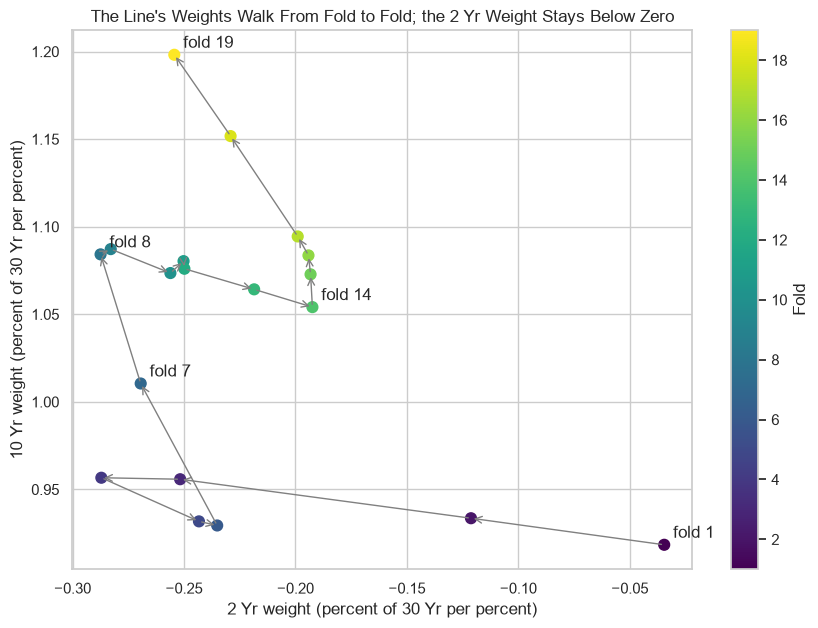

In [34]:
# the line's (2 Yr, 10 Yr) weights fold by fold, coloured by fold and joined by arrows
plt.figure(figsize=(10, 7))
plt.scatter(weights["2 Yr"], weights["10 Yr"], c=weights.index, cmap="viridis", s=60, zorder=3)
plt.colorbar(label="Fold")
for fold in range(1, 19):
    plt.annotate("", xy=weights.loc[fold + 1], xytext=weights.loc[fold], arrowprops={"arrowstyle": "->", "color": "gray"})

# a few folds named; the colour gives the rest
for fold in [1, 7, 8, 14, 19]:
    plt.text(weights.loc[fold, "2 Yr"] + 0.004, weights.loc[fold, "10 Yr"] + 0.004, "fold " + str(fold))
plt.xlabel("2 Yr weight (percent of 30 Yr per percent)")
plt.ylabel("10 Yr weight (percent of 30 Yr per percent)")
plt.title("The Line's Weights Walk From Fold to Fold; the 2 Yr Weight Stays Below Zero")
plt.show()

The 2 Yr weight is below zero in all 19 folds: holding the 10 Yr fixed, a higher 2 Yr goes with a lower fitted 30 Yr (Day 3's words).

The 10 Yr weight runs from 0.918 to 1.198 and steps up between folds 7 and 8, from 1.010 to 1.084.

Q. In the line's three worst folds, are its misses on both sides?

In [35]:
# in the line's three worst folds: each model's mean miss and MAE in bp, and the test dates with a feature outside its training range
rows = []
for fold in [10, 17, 18]:
    fit_rows, scored_rows = splits[fold - 1]
    line_miss = (y.iloc[scored_rows] - line_runs["estimator"][fold - 1].predict(X.iloc[scored_rows])) * 100
    tree_miss = (y.iloc[scored_rows] - tree_runs["estimator"][fold - 1].predict(X.iloc[scored_rows])) * 100
    beyond = ((X.iloc[scored_rows] > X.iloc[fit_rows].max()) | (X.iloc[scored_rows] < X.iloc[fit_rows].min())).any(axis=1).sum()
    rows.append({"fold": fold, "line mean miss": line_miss.mean(), "line MAE": line_miss.abs().mean(),
                 "tree mean miss": tree_miss.mean(), "tree MAE": tree_miss.abs().mean(), "features outside": beyond})
pd.DataFrame(rows).set_index("fold").round(1)

,line mean miss,line MAE,tree mean miss,tree MAE,features outside
fold,,,,,
10,-24.3,24.3,-27.1,27.1,0
17,26.8,26.8,21.6,21.6,0
18,26.4,26.4,34.1,37.9,0


In all three folds no feature leaves its training range, so these are not new levels.

The line's mean miss is as large as its MAE: every miss sits on one side, below the line's value in fold 10 and above it in folds 17 and 18.

The tree misses the same way in folds 10 and 17, and mostly above in fold 18, its worst at 37.9 bp: the plane itself moved.

**Two things make a later fold hard: new levels, which a tree cannot follow, and a relationship that moved, which a model fitted only on earlier dates has never seen. A random split hides both.**

# Ridge and Lasso on Tenor Changes

## A Second Task: Daily Changes

Levels repeat their neighbours; daily changes do not.
The second task fits the 30 Yr's daily change given the same day's changes in the other ten tenors, all in bp.

In [36]:
# each date's change from the date before, in bp; the first date has none
changes = (curve.diff() * 100).dropna()
X_changes = changes.drop(columns="30 Yr")
y_changes = changes["30 Yr"]

## How Closely the Tenors Move Together

`mask=` hides the cells where it is True; `np.triu` keeps the upper triangle, so each pair shows once.

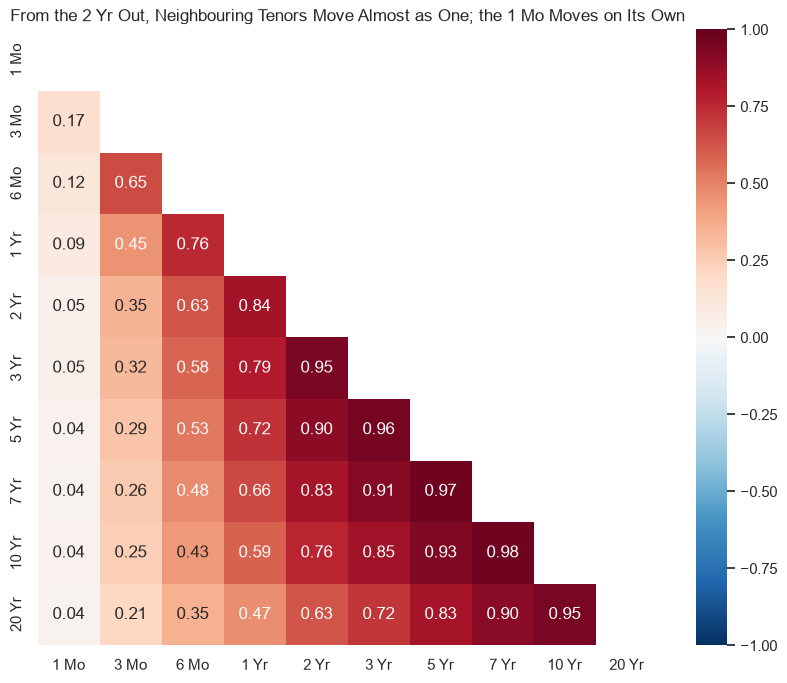

In [37]:
# the correlation of every pair of daily changes, lower triangle only
correlations = X_changes.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(correlations, mask=np.triu(np.ones_like(correlations, dtype=bool)), annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1)
plt.grid(False)
plt.title("From the 2 Yr Out, Neighbouring Tenors Move Almost as One; the 1 Mo Moves on Its Own")
plt.show()

In [38]:
# Day 3's VIF of each column, with the constant in the design
design = sm.add_constant(X_changes)
vif = pd.Series([variance_inflation_factor(design.values, i) for i in range(1, 11)], index=X_changes.columns)
vif.sort_values(ascending=False).round(2)

7 Yr     60.58
10 Yr    52.65
5 Yr     45.63
3 Yr     23.48
20 Yr    16.57
2 Yr     13.05
1 Yr      4.99
6 Mo      3.29
3 Mo      1.79
1 Mo      1.03
dtype: float64

The 20 Yr and 10 Yr changes correlate 0.95, the 7 Yr and 10 Yr 0.98; the 1 Mo correlates 0.17 or less with every other tenor.

Six of the ten VIFs sit above 10, led by the 7 Yr at 60.58.

**Ten near-copies in one model: the setting where Day 5's penalties should earn their keep.**

## Expanding Folds

`make_pipeline` builds Day 5's `Pipeline` and names each step for you, from its class.

In [39]:
# a scaler, then least squares; .steps lists the named steps
ols_pipe = make_pipeline(StandardScaler(), LinearRegression())
ols_pipe.steps

[('standardscaler', StandardScaler()),
 ('linearregression', LinearRegression())]

`pipe[-1]` picks a pipeline's last step, the model.
`RidgeCV` and `LassoCV` choose alpha on their own folds, so each gets `TimeSeriesSplit(n_splits=5)` inside the training dates.

In [40]:
# three pipelines scored on the 19 walk-forward folds by R-squared
pipes = {"least squares": ols_pipe,
         "ridge": make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-3, 3, 25), cv=TimeSeriesSplit(n_splits=5))),
         "lasso": make_pipeline(StandardScaler(), LassoCV(cv=TimeSeriesSplit(n_splits=5), max_iter=10000, random_state=SEED))}
expanding = {name: cross_validate(pipe, X_changes, y_changes, cv=wf, scoring="r2", return_estimator=True, return_indices=True)
             for name, pipe in pipes.items()}
for name, run in expanding.items():
    print(name, ": mean fold R-squared", round(run["test_score"].mean(), 4))
print(pd.Series([model[-1].alpha_ for model in expanding["ridge"]["estimator"]]).round(3).value_counts())

least squares : mean fold R-squared 0.9566
ridge : mean fold R-squared 0.9566
lasso : mean fold R-squared 0.9562
0.001    15
1.778     2
0.562     1
0.178     1
Name: count, dtype: int64


The three tie at about 0.957.

Each pipeline refits its scaler inside every fold, on that fold's training dates only, and ridge and lasso choose alpha on folds inside those dates.

Ridge picks alpha 0.001, the grid's smallest, in 15 of 19 folds, and never more than 1.78: with hundreds of dates, ten collinear weights are already pinned down.

## Rolling 63-Row Windows

A rolling window of 63 dates, about three months, leaves the penalty far fewer rows to work with.

In [41]:
# 115 folds: fit on the 63 dates before, test on the next 21
rolling = TimeSeriesSplit(n_splits=115, test_size=21, max_train_size=63)
rolling_runs = {name: cross_validate(pipe, X_changes, y_changes, cv=rolling, scoring="r2", return_estimator=True)
                for name, pipe in pipes.items()}

# each model's 10 Yr weight in every window, per standard deviation of the 10 Yr change
ten_year = pd.DataFrame({name: [pd.Series(model[-1].coef_, index=X_changes.columns)["10 Yr"] for model in run["estimator"]]
                         for name, run in rolling_runs.items()})
pd.DataFrame({"R-squared": [run["test_score"].mean() for run in rolling_runs.values()], "weight std": ten_year.std(),
              "below zero": (ten_year < 0).sum(), "at zero": (ten_year == 0).sum()}, index=pipes).round(4)

,R-squared,weight std,below zero,at zero
least squares,0.9401,1.6500,13,0
ridge,0.9414,1.1373,5,0
lasso,0.9423,0.9519,0,55


A **beeswarm**, Course 1's `sns.swarmplot`, sets every point beside its neighbours so none hides another.

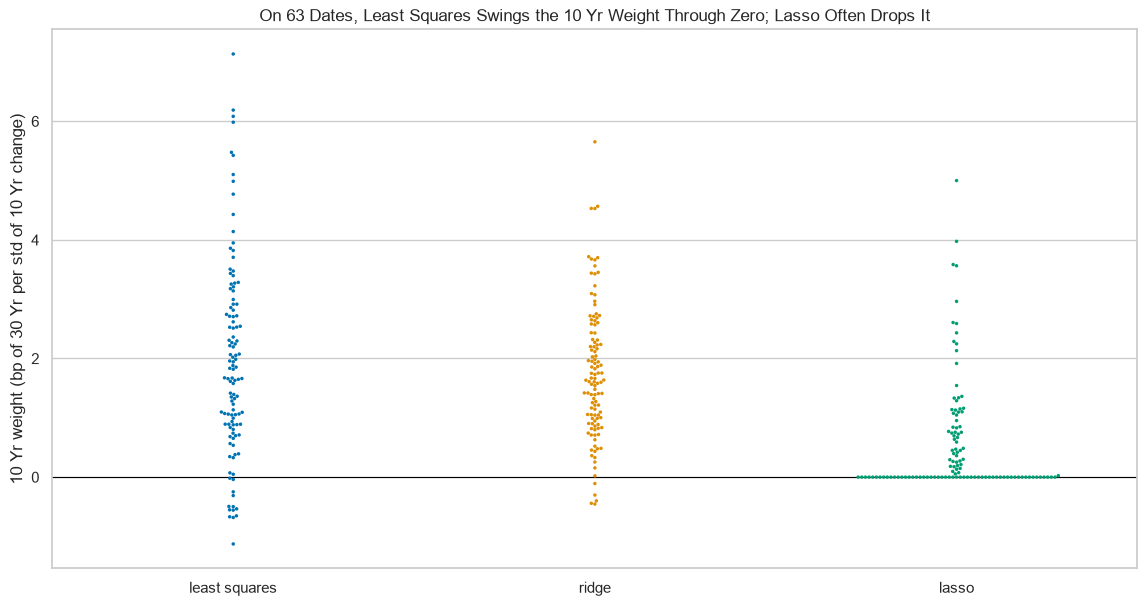

In [42]:
# the 115 window weights of the 10 Yr for each model
plt.figure(figsize=(14, 7))
sns.swarmplot(data=ten_year, size=2.5)
plt.axhline(0, color="black", linewidth=0.8)
plt.ylabel("10 Yr weight (bp of 30 Yr per std of 10 Yr change)")
plt.title("On 63 Dates, Least Squares Swings the 10 Yr Weight Through Zero; Lasso Often Drops It")
plt.show()

On 63 dates the 10 Yr weight's spread falls from 1.65 (least squares) to 1.14 (ridge) and 0.95 (lasso).

Least squares puts it below zero in 13 windows; lasso never does, and drops the 10 Yr altogether in 55.

The three mean R-squared values stay within 0.003.

**Shrinkage steadies the weights when rows are few and features are near-copies; with hundreds of rows or more it changes almost nothing.**

# Lookahead in Features

## Two Z-Scores of the 2s10s Slope

Course 3's trailing z-score measures a date against the 252 dates up to it.
A whole-history z-score uses the mean and spread of every date in the file, later ones included.

In [43]:
# the 2s10s slope in bp, and two z-scores of it
slope_bp = (curve["10 Yr"] - curve["2 Yr"]) * 100

def whole_z(s):
    return (s - s.mean()) / s.std()

def trailing_z(s):
    return (s - s.rolling(252).mean()) / s.rolling(252).std()

## The Cut Test

Course 3's no-lookahead test, the cut test: stop the data on a cut date, recompute, and compare.
A number that changes used dates after the cut.

In [44]:
# the slope stopped on 2019-12-31, and both z-scores on that date, with every date and stopped there
stopped = slope_bp.loc[:"2019-12-31"]
print("Whole-history z: with every date", round(whole_z(slope_bp)["2019-12-31"], 4), " stopped", round(whole_z(stopped)["2019-12-31"], 4))
print("Trailing z:      with every date", round(trailing_z(slope_bp)["2019-12-31"], 4), " stopped", round(trailing_z(stopped)["2019-12-31"], 4))
print("Whole-history values up to the cut that change:", (whole_z(slope_bp).loc[:"2019-12-31"] != whole_z(stopped)).sum(), "of", len(stopped))

Whole-history z: with every date -0.2303  stopped -0.9311
Trailing z:      with every date 2.3634  stopped 2.3634
Whole-history values up to the cut that change: 1250 of 1250


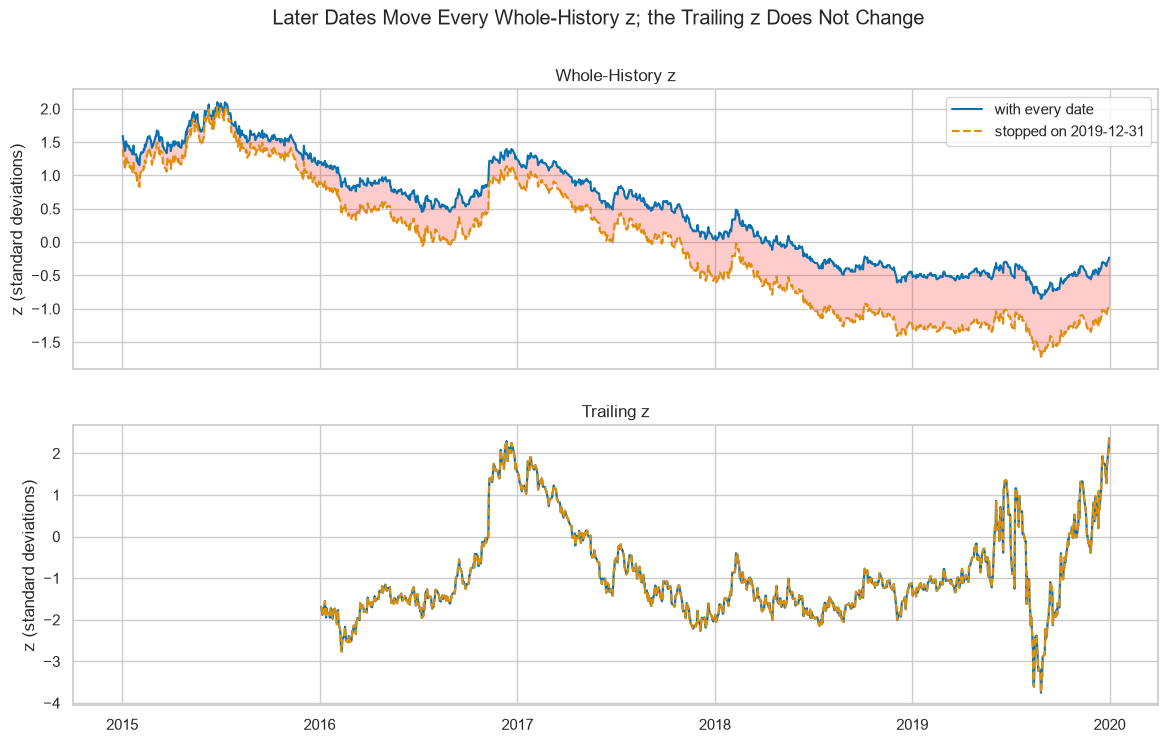

In [45]:
# both z-scores up to the cut, computed with every date and stopped at the cut; the gap shaded
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
for ax, z, name in [(axes[0], whole_z, "Whole-History z"), (axes[1], trailing_z, "Trailing z")]:
    with_all, cut_off = z(slope_bp).loc[:"2019-12-31"], z(stopped)
    ax.plot(with_all, label="with every date")
    ax.plot(cut_off, linestyle="--", label="stopped on 2019-12-31")
    ax.fill_between(cut_off.index, with_all, cut_off, color="red", alpha=0.2)
    ax.set(ylabel="z (standard deviations)", title=name)
axes[0].legend()
fig.suptitle("Later Dates Move Every Whole-History z; the Trailing z Does Not Change")
plt.show()

On 2019-12-31 the whole-history z is -0.2303 with every date and -0.9311 stopped there: the later dates moved it.

All 1,250 whole-history values up to the cut change; the trailing z is 2.3634 both ways.

**Walk-forward keeps later dates out of training; a feature built from the whole history carries them back in.**

# Misses That Run

## Durbin-Watson

The **Durbin-Watson** statistic sums the squared step from each miss to the next and divides by the sum of the squared misses.
It is about 2 when a miss is unrelated to the one before, near 0 when each miss copies the last, and near 4 when each miss takes the other sign from the last.

In [46]:
# the line's walk-forward misses on levels, in bp, in date order
level_misses = pd.concat([(y.iloc[rows] - model.predict(X.iloc[rows])) * 100
                          for model, rows in zip(line_runs["estimator"], line_runs["indices"]["test"])])

# Durbin-Watson, and how often a miss has the other sign from the one before
print("Durbin-Watson:", round(durbin_watson(level_misses), 3))
print("Sign changes:", (level_misses * level_misses.shift() < 0).sum(), "in", len(level_misses), "dates")

Durbin-Watson: 0.011
Sign changes: 27 in 2394 dates


**Predict 4**

Level misses run, Durbin-Watson 0.011.

Q. What Durbin-Watson do the changes model's walk-forward misses give? Write down a number.

In [47]:
# least squares on changes: its walk-forward misses in bp, in date order
change_run = expanding["least squares"]
change_misses = pd.concat([y_changes.iloc[rows] - model.predict(X_changes.iloc[rows])
                           for model, rows in zip(change_run["estimator"], change_run["indices"]["test"])])
print("Durbin-Watson:", round(durbin_watson(change_misses), 3))
print("Sign changes:", (change_misses * change_misses.shift() < 0).sum(), "in", len(change_misses), "dates")

Durbin-Watson: 2.426
Sign changes: 1446 in 2394 dates


A **diverging area chart** fills above zero in one colour and below in another; `fill_between(where=)` fills only where the condition holds.

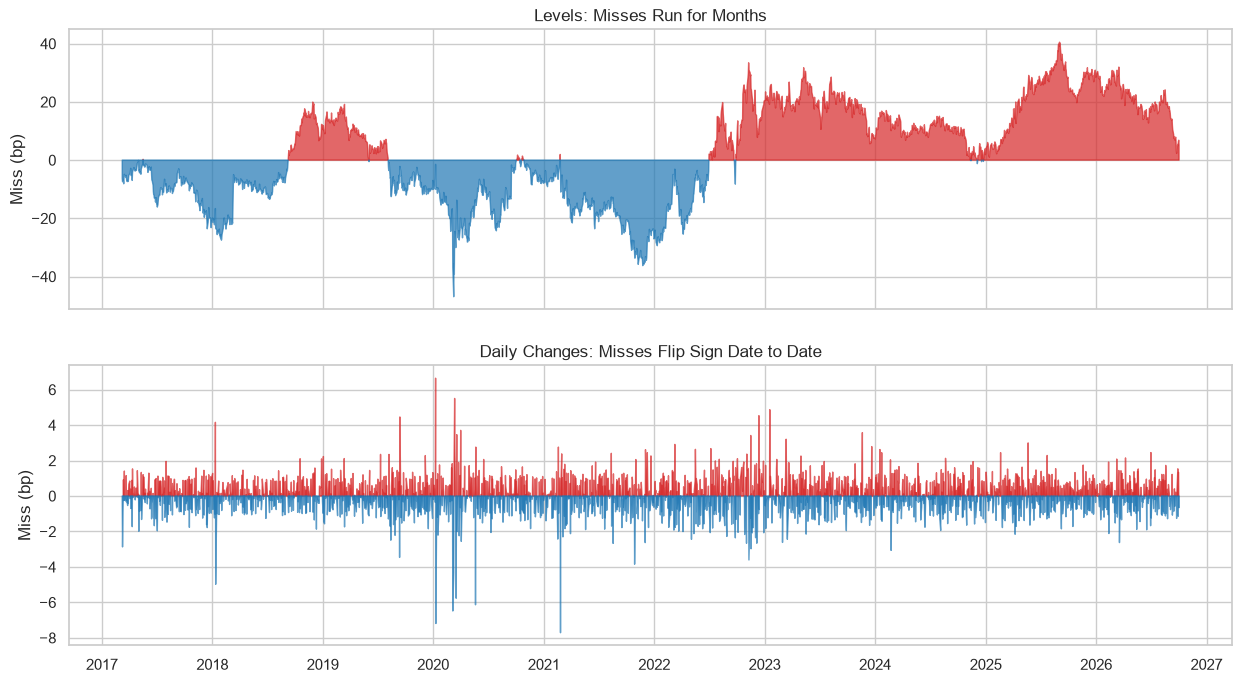

In [48]:
# each model's misses over time: red above zero, blue below
fig, axes = plt.subplots(2, 1, figsize=(15, 8), sharex=True)
for ax, misses, name in [(axes[0], level_misses, "Levels: Misses Run for Months"), (axes[1], change_misses, "Daily Changes: Misses Flip Sign Date to Date")]:
    ax.fill_between(misses.index, misses, 0, where=misses > 0, color="tab:red", alpha=0.7, interpolate=True)
    ax.fill_between(misses.index, misses, 0, where=misses < 0, color="tab:blue", alpha=0.7, interpolate=True)
    ax.set(ylabel="Miss (bp)", title=name)
plt.show()

Level misses change sign 27 times in 2,394 dates: 19 folds of runs are far less evidence than 2,394 separate tries.

Change misses change sign 1,446 times, and their Durbin-Watson of 2.43 sits near 2.

# Insights and Conclusion

Shuffled folds scored the tree at 4.45 bp and walk-forward at 14.84, and the ranking against the line flipped.

A tree stays inside the range of its training yields, and both models miss when the relationship moves.

Shrinkage pays only with few rows and near-copy features.

Lookahead hides in features as well as in rows, and the cut test finds it.

Everything here describes this file inside its span, 2015 to 2026.

**On dated rows, score in time order, or the score measures memory.**

# Wrapping Up

## You Can Now

By the end of this notebook, you can:

* Read lag plots and a correlogram, and say why a shuffled split flatters a model on dates.
* Score a model walk-forward with `TimeSeriesSplit` and `cross_validate`, and read the spread across folds.
* Say what a regression tree does with a date outside its training range.
* Fit ridge and lasso with `make_pipeline` on expanding and rolling windows.
* Find lookahead with the cut test, and read a Durbin-Watson statistic.

## Exercises

Run this cell first: `check()` marks each answer as correct, not yet, or not attempted.

In [49]:
# check() compares your answer with the expected one
def check(label, answer, expected):
    if answer is ...:
        print(label + ": not attempted yet")
    elif isinstance(expected, float) and abs(answer - expected) < 1e-6:
        print(label + ": correct")
    elif answer == expected:
        print(label + ": correct")
    else:
        print(label + ": not yet. You have", answer)

### Exercise 1

**The 20 Yr From the 5 Yr and the 10 Yr**

Q. Score a `LinearRegression` and a `DecisionTreeRegressor(random_state=SEED)` that fit the 20 Yr given the same day's 5 Yr and 10 Yr, on the walk-forward folds `wf`.
Store each one's mean fold MAE in bp in `ex1_line_bp` and `ex1_tree_bp`.

In [50]:
# the same day's 5 Yr and 10 Yr as features, the same day's 20 Yr as the target, in percent
X_20, y_20 = curve[["5 Yr", "10 Yr"]], curve["20 Yr"]

# both models walk-forward, then on the shuffled folds for comparison, in bp
ex1_line_bp = (-cross_val_score(line, X_20, y_20, cv=wf, scoring="neg_mean_absolute_error") * 100).mean()
ex1_tree_bp = (-cross_val_score(tree, X_20, y_20, cv=wf, scoring="neg_mean_absolute_error") * 100).mean()
shuffled_line = (-cross_val_score(line, X_20, y_20, cv=kfold, scoring="neg_mean_absolute_error") * 100).mean()
shuffled_tree = (-cross_val_score(tree, X_20, y_20, cv=kfold, scoring="neg_mean_absolute_error") * 100).mean()
print("Walk-forward: line", round(ex1_line_bp, 2), " tree", round(ex1_tree_bp, 2))
print("Shuffled:     line", round(shuffled_line, 2), " tree", round(shuffled_tree, 2))

Walk-forward: line 10.7  tree 10.78
Shuffled:     line 8.85  tree 3.38


Walk-forward the line and the tree are close; shuffled folds hand the tree a far smaller miss, the same near-copy effect as for the 30 Yr.

In [51]:
check("Exercise 1 the line's walk-forward MAE", ex1_line_bp, 10.697393149717385)
check("Exercise 1 the tree's walk-forward MAE", ex1_tree_bp, 10.780590364800888)

Exercise 1 the line's walk-forward MAE: correct
Exercise 1 the tree's walk-forward MAE: correct


### Exercise 2

**A Gap of 21 Dates**

Q. Make `TimeSeriesSplit(n_splits=19, test_size=126, gap=21)` and score the tree that fits the 30 Yr given the 2 Yr and 10 Yr on it.
Store its mean fold MAE in bp in `ex2_tree_bp`.

In [52]:
# 19 folds with 21 unused dates between each training window and its test window
gapped = TimeSeriesSplit(n_splits=19, test_size=126, gap=21)
ex2_tree_bp = (-cross_val_score(tree, X, y, cv=gapped, scoring="neg_mean_absolute_error") * 100).mean()
print("Tree:", round(ex2_tree_bp, 2), "bp  first training window:", len(next(gapped.split(X))[0]), "dates")

Tree: 20.02 bp  first training window: 525 dates


The gap ends every training window 21 dates before its test window starts, and the tree's miss rises from 14.84 bp to 20.02.

The first window shrinks by the 21 dates the gap takes.

In [53]:
check("Exercise 2 the tree's MAE with a gap", ex2_tree_bp, 20.02109440267335)

Exercise 2 the tree's MAE with a gap: correct


### Exercise 3

**A Table of Fold Dates**

Q. Write `fold_dates(dates, splits)`: it returns a DataFrame with one row per fold, numbered from 1, and the columns `train_first`, `train_last`, `test_first` and `test_last`.
Use it on `curve.index` and `splits`, and store fold 7's first test date, as text such as "2015-01-02", in `ex3_test_first`.

In [54]:
# one row per fold: the first and last date of its training window and of its test window
def fold_dates(dates, splits):
    rows = []
    for fit_rows, scored_rows in splits:
        rows.append({"train_first": dates[fit_rows[0]], "train_last": dates[fit_rows[-1]],
                     "test_first": dates[scored_rows[0]], "test_last": dates[scored_rows[-1]]})
    return pd.DataFrame(rows, index=range(1, len(rows) + 1))

fold_table_dates = fold_dates(curve.index, splits)
ex3_test_first = str(fold_table_dates.loc[7, "test_first"].date())
fold_table_dates.loc[[1, 7, 19]]

,train_first,train_last,test_first,test_last
1,2015-01-02,2017-03-08,2017-03-09,2017-09-06
7,2015-01-02,2020-03-17,2020-03-18,2020-09-15
19,2015-01-02,2026-04-03,2026-04-06,2026-10-02


Each training window ends the date before its test window starts, and every one starts on 2015-01-02.

In [55]:
check("Exercise 3 fold 7's first test date", ex3_test_first, "2020-03-18")

Exercise 3 fold 7's first test date: correct


### Exercise 4: AI check

**Five Folds in Time Order**

You asked an AI assistant for a function that scores a model on five folds in time order.
This came back.
It runs, and it returns a number.

In [56]:
# written for this course in the style of an AI assistant's answer: it runs, and it has one bug
def walk_forward_mae(model, X, y):
    """MAE in bp over five folds in time order: every fold fitted on dates before every date it is tested on."""
    folds = list(KFold(n_splits=5, shuffle=True, random_state=SEED).split(X))
    scores = -cross_val_score(model, X, y, cv=folds, scoring="neg_mean_absolute_error") * 100
    return folds, scores.mean()

ai_folds, ai_mae = walk_forward_mae(DecisionTreeRegressor(random_state=SEED), X, y)
print(round(ai_mae, 2), "bp")

4.45 bp


Test the promise before trusting the number.

In [57]:
# the test, written from the docstring: each fold's last training date comes before its first test date
for fit_rows, scored_rows in ai_folds:
    last_train, first_test = X.index[fit_rows].max(), X.index[scored_rows].min()
    assert last_train < first_test, "training runs to " + str(last_train.date()) + ", testing starts " + str(first_test.date())

AssertionError: training runs to 2026-10-01, testing starts 2015-01-21

Q. Which line breaks the promise? Fix it, and store the fixed function's MAE in bp in `ex4_tree_bp`.

In [58]:
# the fix: five folds in time order, never shuffled
def walk_forward_mae(model, X, y):
    """MAE in bp over five folds in time order: every fold fitted on dates before every date it is tested on."""
    folds = list(TimeSeriesSplit(n_splits=5).split(X))
    scores = -cross_val_score(model, X, y, cv=folds, scoring="neg_mean_absolute_error") * 100
    return folds, scores.mean()

ai_folds, ex4_tree_bp = walk_forward_mae(DecisionTreeRegressor(random_state=SEED), X, y)

# the same test, now passing
for fit_rows, scored_rows in ai_folds:
    assert X.index[fit_rows].max() < X.index[scored_rows].min()
print("Every fold trains before it tests. MAE:", round(ex4_tree_bp, 2), "bp")

Every fold trains before it tests. MAE: 23.03 bp


The shuffled `KFold` line broke the promise: its first fold trained on dates up to 2026-10-01 and tested from 2015-01-21.

The leaky version reported 4.45 bp; in time order the same tree misses by 23.03 bp, the number the five folds in time order gave earlier.

A docstring is a promise, and a test of the promise caught what the number could not.

In [59]:
check("Exercise 4 the fixed MAE", ex4_tree_bp, 23.025102040816325)

Exercise 4 the fixed MAE: correct


## Congratulations!

You scored the same two models twice today and watched the verdict flip.
Shuffled folds called the tree a 4.45 bp model; walk-forward folds showed 14.84 bp, and a Gantt chart showed when it failed.
You found two reasons: a tree cannot leave its training range, and a line's plane drifts.
Then you tested shrinkage, caught lookahead with the cut test, and watched misses run.
On Day 12 the target goes away: k-means groups bonds by their numbers alone.

[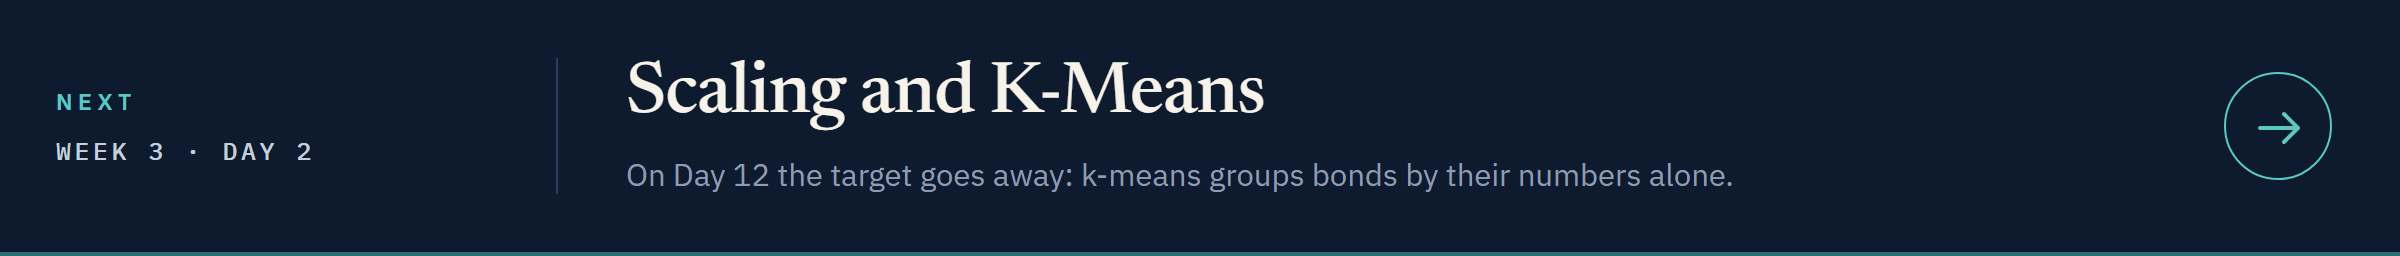](../day2/12_scaling_and_k_means.ipynb)

[Open Day 2 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course04_machine_learning/week3/day2/12_scaling_and_k_means.ipynb)